# Progetto: Previsione del Consumo Energetico con Modelli Classici e Ricorrenti

### di Lavinia Solimani

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import zscore
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import itertools
import warnings
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, LSTM, Dropout, Dense, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import joblib
import os
import json
!pip install keras_tuner
import keras_tuner as kt
from statsmodels.stats.diagnostic import acorr_ljungbox
from PIL import Image
%matplotlib inline
sns.set_theme(style = 'whitegrid')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.9 MB/s eta 0:00:00


In [ ]:
!wget https://raw.githubusercontent.com/Profession-AI/progetti-ml/refs/heads/main/Previsione%20del%20Consumo%20Energetico%20con%20Modelli%20Classici%20e%20Ricorrenti/clustered_hourly_values_all.csv

--2026-07-18 08:57:01--  https://raw.githubusercontent.com/Profession-AI/progetti-ml/refs/heads/main/Previsione%20del%20Consumo%20Energetico%20con%20Modelli%20Classici%20e%20Ricorrenti/clustered_hourly_values_all.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7407539 (7.1M) [text/plain]
Saving to: ‘clustered_hourly_values_all.csv’

clustered_hourly_va 100%[===================>]   7.06M  --.-KB/s    in 0.07s   

2026-07-18 08:57:01 (107 MB/s) - ‘clustered_hourly_values_all.csv’ saved [7407539/7407539]



## 1. Analisi esplorativa e pulizia delle serie temporali

In [ ]:
df = pd.read_csv('clustered_hourly_values_all.csv')
df = df[['row ID', 'cluster_26', 'cluster_9', 'cluster_24']]
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12838 entries, 0 to 12837
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   row ID      12838 non-null  object 
 1   cluster_26  12838 non-null  float64
 2   cluster_9   12838 non-null  float64
 3   cluster_24  12838 non-null  float64
dtypes: float64(3), object(1)
memory usage: 401.3+ KB


In [ ]:
df.head()

,row ID,cluster_26,cluster_9,cluster_24
0,2009-07-15_00,3.254085,1.037702,0.777450
1,2009-07-15_01,3.197561,0.730954,0.591275
2,2009-07-15_02,3.038390,0.518665,0.483900
3,2009-07-15_03,3.029756,0.423768,0.353325
4,2009-07-15_04,3.005634,0.382569,0.378625


Verifichiamo l'eventuale presenza di valori duplicati.

In [ ]:
df.duplicated().any()

np.False_

La colonna "row_ID" mostra la data e l'ora della rilevazione, dove ogni riga rappresenta un'ora. La convertiamo in formato *datetime* e la impostiamo come indice, dopodiché verifichiamo che non vi siano ore mancanti.

In [ ]:
# Datetime column parsing
df['datetime'] = pd.to_datetime(df['row ID'], format = '%Y-%m-%d_%H')
df.set_index('datetime', inplace = True)
df.drop(columns = ['row ID'], inplace = True)

# Reindex of DataFrame to have the full time range and account for any missing values
full_range = pd.date_range(start = df.index.min(), end = df.index.max(), freq = 'h')
df = df.reindex(full_range)

# Missing values
print(df.isna().sum())
print("\nRows with missing values:")
print(df[df.isna().any(axis = 1)])

cluster_26    2
cluster_9     2
cluster_24    2
dtype: int64

Rows with missing values:
                     cluster_26  cluster_9  cluster_24
2010-03-28 01:00:00         NaN        NaN         NaN
2010-03-29 01:00:00         NaN        NaN         NaN


Risultano quindi due valori mancanti, corrispondenti a due rilevazioni orarie a fine marzo 2010. Probabilmente, la causa è il passaggio dall'ora solare all'ora legale. Li gestiamo mediante un'imputazione con interpolazione lineare.

In [ ]:
df = df.interpolate(method = 'linear')

print(df.isna().sum())
print("\nRows with missing values:")
print(df[df.isna().any(axis = 1)])

cluster_26    0
cluster_9     0
cluster_24    0
dtype: int64

Rows with missing values:
Empty DataFrame
Columns: [cluster_26, cluster_9, cluster_24]
Index: []


In [ ]:
df.shape

(12840, 3)

Abbiamo quindi un dataset con 12.840 righe.

In [ ]:
df.describe()

,cluster_26,cluster_9,cluster_24
count,12840.000000,12840.000000,12840.000000
mean,7.209933,1.173150,0.707299
std,4.999091,0.627166,0.390964
min,2.457593,0.330619,0.135774
25%,3.548706,0.588824,0.410935
50%,4.470003,1.091790,0.592541
75%,10.923439,1.606125,0.921238
max,23.273883,3.571644,2.711129


### 1.1 Rappresentazione grafica e analisi della stazionarietà

Definiamo una funzione per eseguire il test statistico Augmented Dickey-Fuller (ADF) sulle serie, e verificarne così la stazionarietà.

In [ ]:
def DickeyFuller(series):

  """
  This function applies the ADF test to a time series, in order to verify its stationarity.
  """

  result = adfuller(series)
  ADFStat = result[0]
  pv = result[1]
  print('ADF Statistic', ADFStat)
  print('p-value', pv, '\n')
  if pv <= 0.05:
    print('Stationary Time Series')
  else:
    print('Non-stationary Time Series')


df_clusters = ['cluster_26', 'cluster_9', 'cluster_24']

for col in df_clusters:
  print(f'--- {col} ---')
  result = DickeyFuller(df[col])
  print()

--- cluster_26 ---
ADF Statistic -14.425588804580988
p-value 7.781941702634576e-27 

Stationary Time Series

--- cluster_9 ---
ADF Statistic -4.589448994678034
p-value 0.00013507897795340547 

Stationary Time Series

--- cluster_24 ---
ADF Statistic -18.005586403865166
p-value 2.7252154638981894e-30 

Stationary Time Series



Tutte e tre le serie, quindi, risultano stazionarie.

Rappresentiamo graficamente le tre serie temporali. Poiché l'intervallo temporale è molto ampio e la rilevazione è stata eseguita a cadenza oraria, le serie contengono un alto numero di valori. Per questo motivo, includiamo nei grafici i primi 500 valori, che dovrebbero essere sufficienti per fornire un'idea del trend e della stagionalità (considerato che una settimana corrisponderà a 24 * 7 = 168 valori).

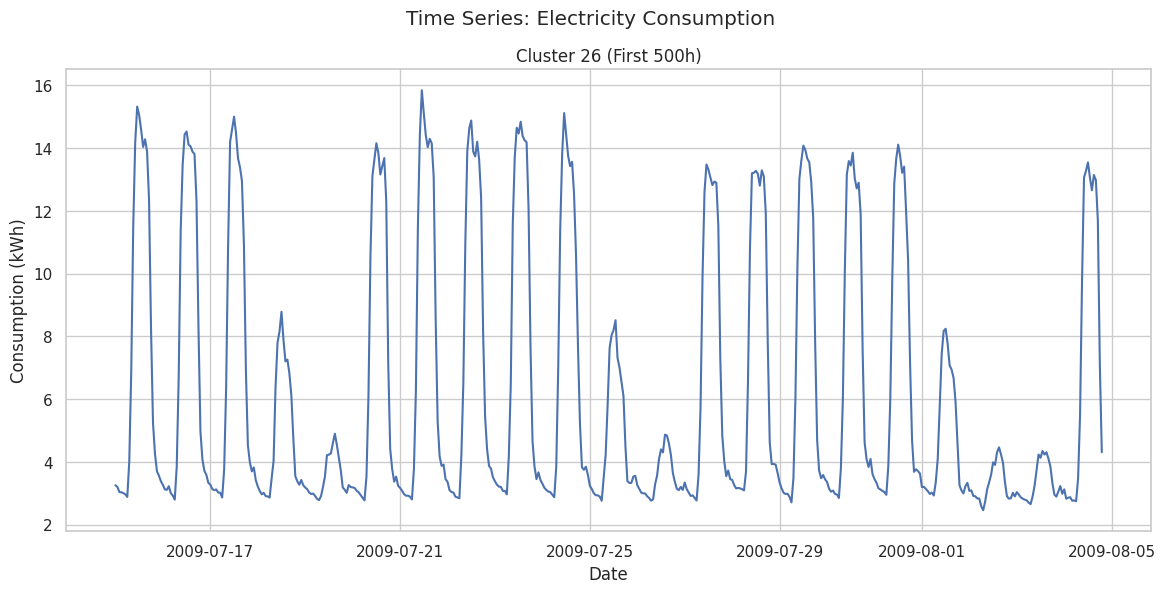

In [ ]:
main_title = 'Time Series: Electricity Consumption'

plt.figure(figsize = (14, 6))
plt.plot(df.index[:500], df['cluster_26'][:500])
plt.suptitle(main_title)
plt.title('Cluster 26 (First 500h)')
plt.xlabel('Date')
plt.ylabel('Consumption (kWh)')
plt.savefig('cluster_26.png');

Dal grafico possiamo confermare la stagionalità giornaliera (24h) e settimanale (168h), entrambe marcate. Inoltre, si nota la differenza dei consumi tra giorni feriali e weekend.

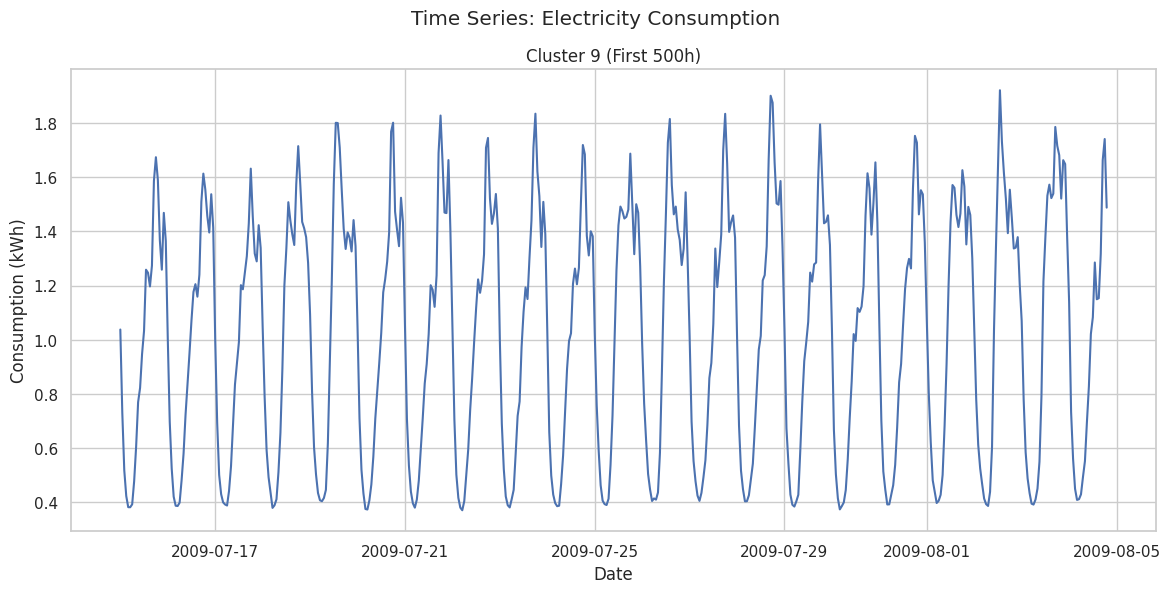

In [ ]:
plt.figure(figsize = (14, 6))
plt.plot(df.index[:500], df['cluster_9'][:500])
plt.suptitle(main_title)
plt.title('Cluster 9 (First 500h)')
plt.xlabel('Date')
plt.ylabel('Consumption (kWh)')
plt.savefig('cluster_9.png');

Dal grafico si confermano la presenza di stagionalità giornaliera (24h) e l'assenza di stagionalità settimanale. Infatti, l'andamento risulta simile in tutti i giorni della settimana, senza distinzione tra giorni feriali e weekend.

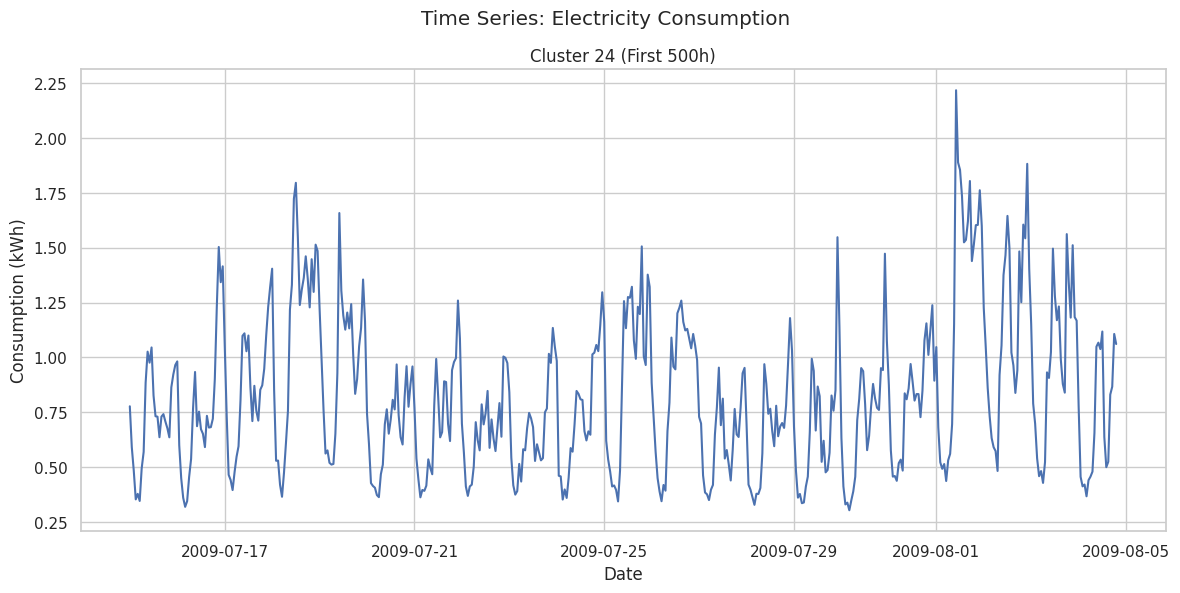

In [ ]:
plt.figure(figsize = (14, 6))
plt.plot(df.index[:500], df['cluster_24'][:500])
plt.suptitle(main_title)
plt.title('Cluster 24 (First 500h)')
plt.xlabel('Date')
plt.ylabel('Consumption (kWh)')
plt.savefig('cluster_24.png');

Da questo grafico non risultano alcun pattern o stagionalità evidenti.

### 1.2 Series Decomposition

Definiamo una funzione per la scomposizione stagionale di ciascuna delle tre serie.

In [ ]:
def plot_seasonal_decomposition(df, cluster, period = 24, limit = 500, model = 'add'):

    """
    This function performs the seasonal decomposition and plots 4 graphs
    (Observed, Trend, Seasonal, Residuals).
    """

    # Extract data portion and execute seasonal decomposition
    ts_slice = df[cluster].iloc[:limit]
    result = seasonal_decompose(ts_slice, model = model, period = period)

    # Define the components to plot
    components = [
        (result.observed, 'b', 'Observed'),
        (result.trend, 'g', 'Trend'),
        (result.seasonal, 'r', 'Seasonal'),
        (result.resid, 'k', 'Residuals')
    ]

    # Plot data
    plt.figure(figsize = (12, 14))

    for i, (data, color, label) in enumerate(components, 1):
        plt.subplot(4, 1, i)
        plt.plot(ts_slice.index, data, color = color, label = label)
        plt.ylabel('Value')
        plt.legend(loc = 'upper right')

        # Add the main title above the first plot
        if i == 1:
            plt.title(f'Seasonal Decomposition - {cluster.replace('_', ' ').title()}', fontsize = 14)

    plt.tight_layout()

    # Save plots
    filename = f'{cluster}_decomp.png'
    plt.savefig(filename)
    plt.show()

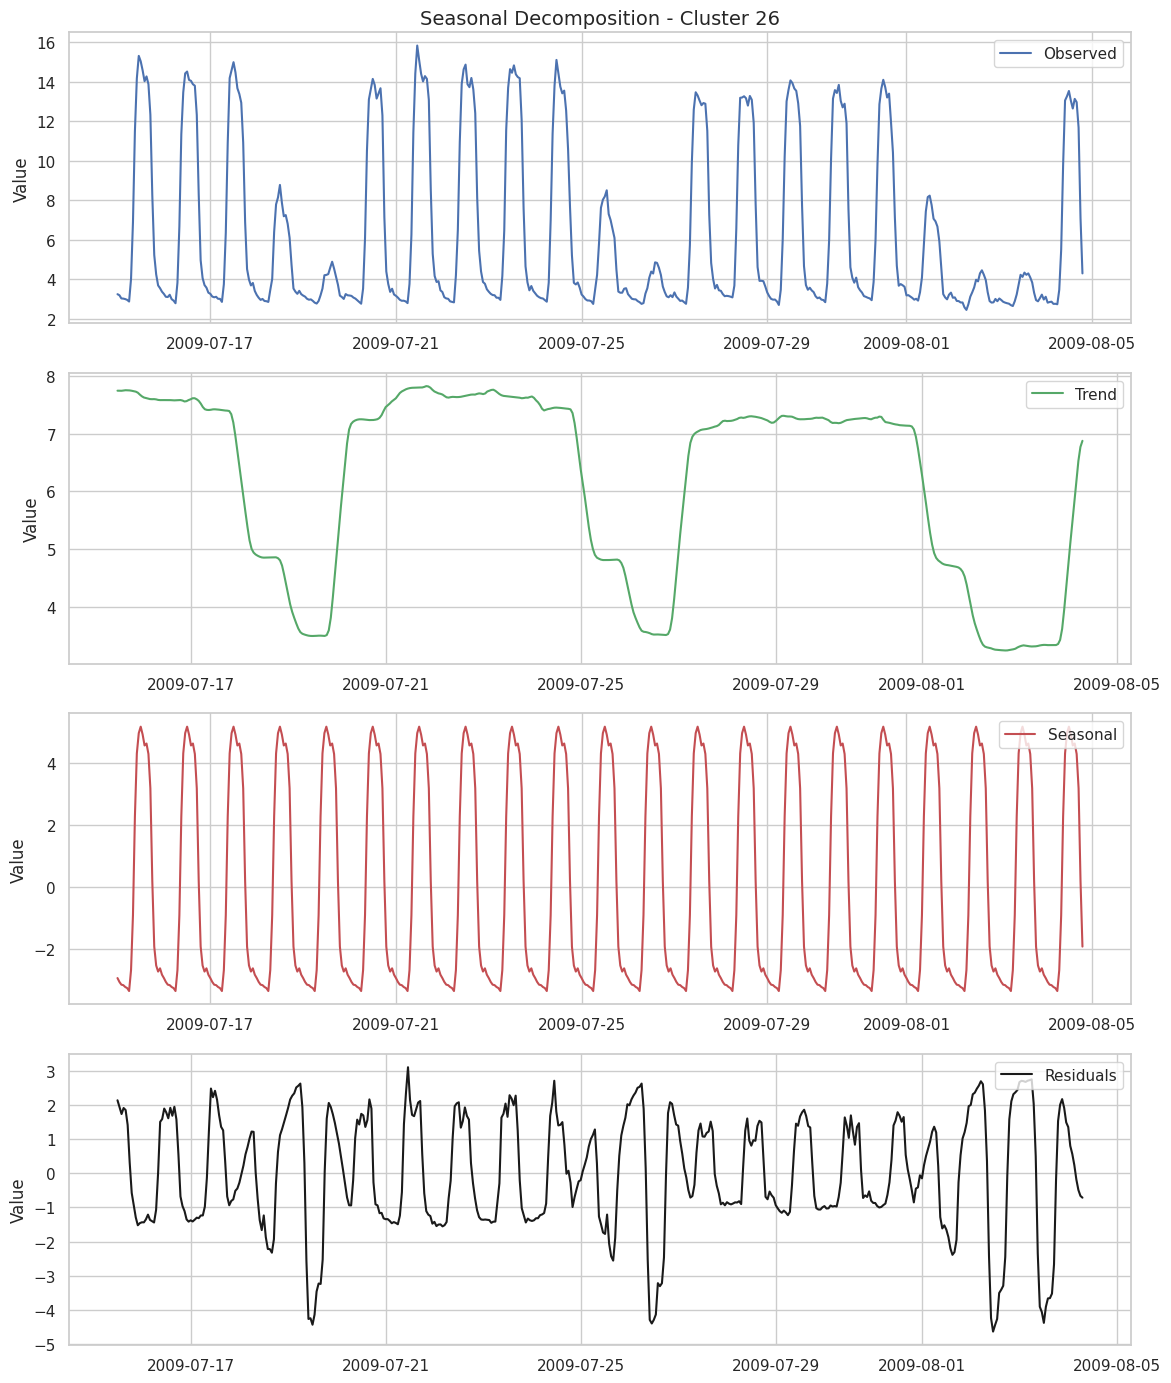

In [ ]:
plot_seasonal_decomposition(df = df, cluster = 'cluster_26')

Dalla decomposizione di questa prima serie riusciamo a cogliere l'andamento che differenzia i giorni feriali e i weekend, nonché la stagionalità giornaliera, che appare con una ricorrenza perfetta. I residui, invece, non sembrano avere un pattern specifico.

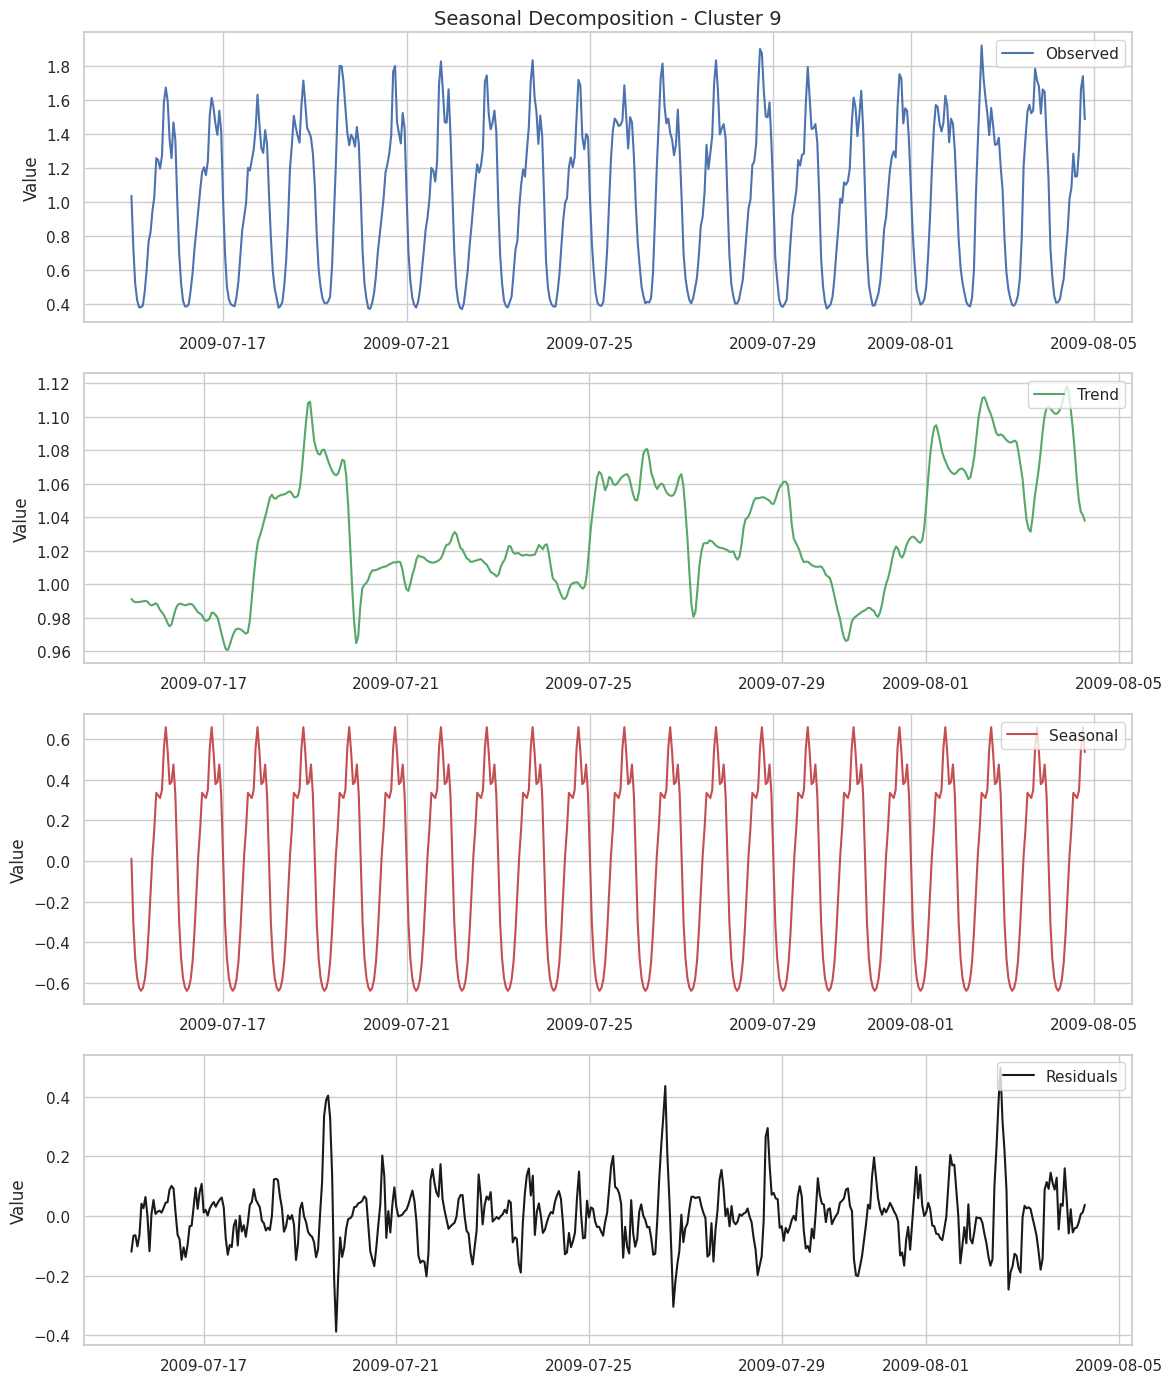

In [ ]:
plot_seasonal_decomposition(df = df, cluster = 'cluster_9')

Dalla decomposizione della seconda serie notiamo l'assenza di un trend, mentre la stagionalità segue una ricorrenza giornaliera sempre identica. Anche in questo caso, i residui non seguono un pattern preciso.

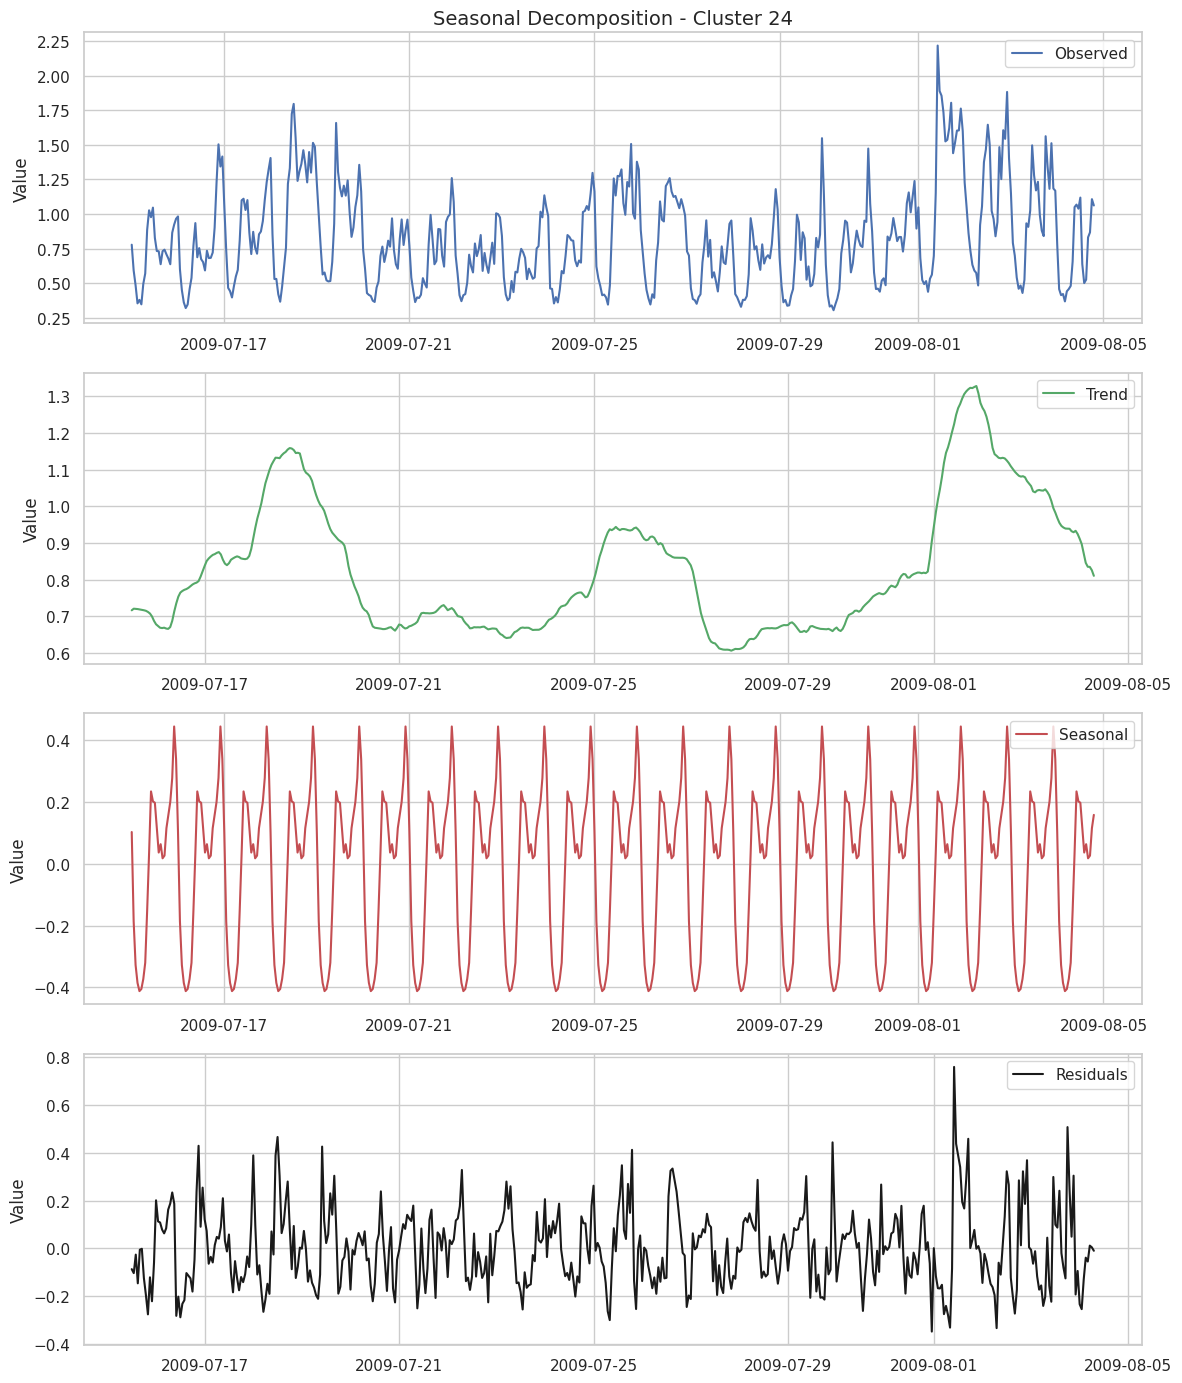

In [ ]:
plot_seasonal_decomposition(df = df, cluster = 'cluster_24')

Decomponendo questa terza serie, notiamo che anch'essa presenta una stagionalità ricorrente, che non si riusciva a cogliere guardando semplicemente il dato osservato.

### 1.3 Calcolo e visualizzazione delle medie mobili

Definiamo una funzione per il calcolo e la visualizzazione delle medie mobili per ciascun cluster.

In [ ]:
def plot_moving_averages(df, cluster, limit = 500):

    """
    This function plots observed data against 24h and 168h moving averages
    for a given cluster.
    """

    # Extract data portion and define figure size
    ts_slice = df[cluster].iloc[:limit]
    plt.figure(figsize = (12, 6))

    # Plot observed data
    plt.plot(ts_slice, label = 'Observed Time Data', alpha = .5, c = 'b')

    # Plot moving averages
    plt.plot(ts_slice.rolling(window = 24, min_periods = 1).mean(),
             label = 'Moving Average 24h (Daily)', linewidth = 2, c = 'r')

    plt.plot(ts_slice.rolling(window = 168, min_periods = 1).mean(),
             label = 'Moving Average 168h (Weekly)', linewidth = 2, c = 'g')

    # Define titles
    cluster_name = cluster.replace('_', ' ').title()
    plt.title(f'Moving Average Analysis - {cluster_name} (First {limit}h)', fontsize = 14)
    plt.ylabel('Consumption (kWh)')
    plt.legend()
    plt.tight_layout()

    # Save graph
    filename = f'{cluster}_ma.png'
    plt.savefig(filename)
    plt.show()

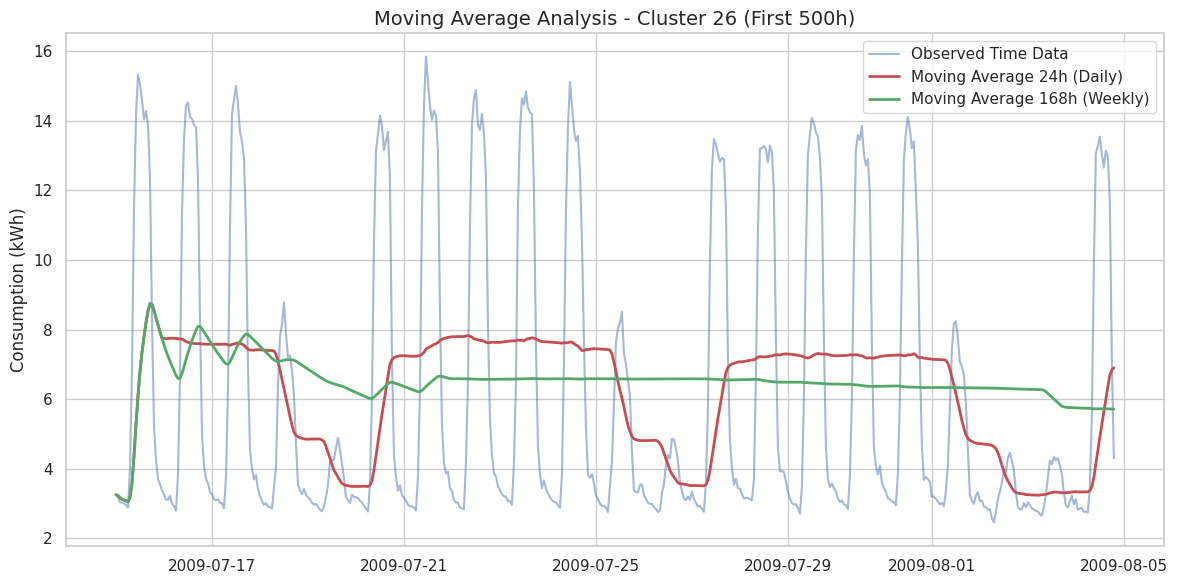

In [ ]:
plot_moving_averages(df = df, cluster = 'cluster_26')

Dal dato osservato si nota una forte variabilità nel consumo energetico, con valori che passano da un minimo di circa 3 a un massimo di circa 16 kWh. La curva relativa alla media mobile a 24h presenta delle onde ricorrenti, indicando la differenza nei consumi tra i giorni feriali e i weekend. La curva relativa alla media mobile a 168h, invece, risulta piatta e con un andamento stabile.

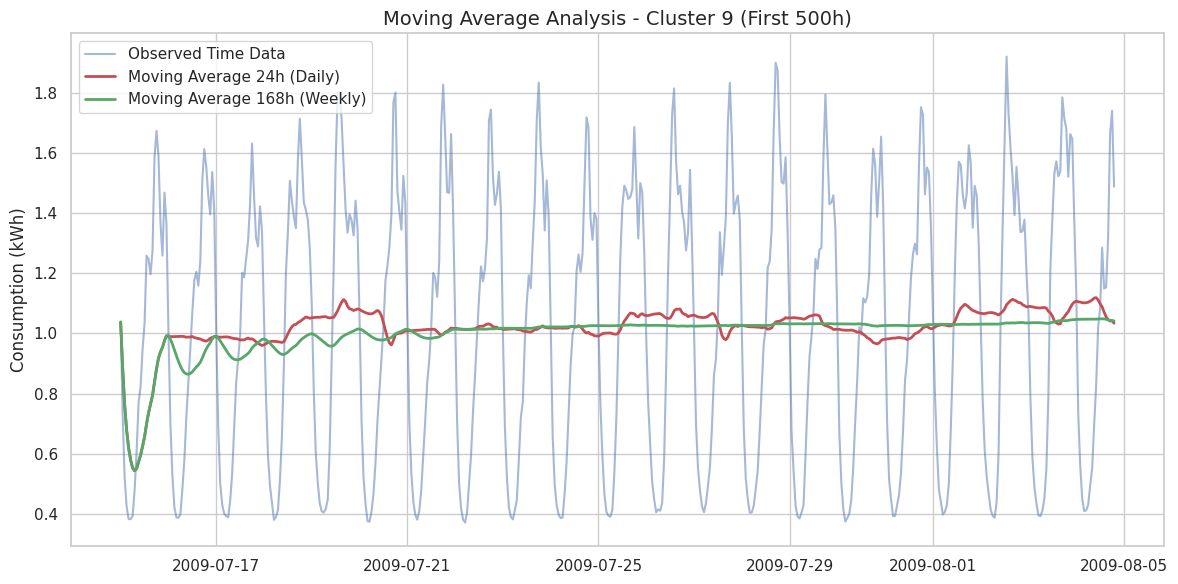

In [ ]:
plot_moving_averages(df = df, cluster = 'cluster_9')

Dal dato osservato risultano consumi energetici nettamente più bassi rispetto al cluster precedente, con un minimo di circa 0.4 e un massimo di circa 1.9 kWh, senza alcuna distinzione tra giorni feriali e weekend. La curva relativa alla media mobile a 24h risulta molto più piatta in questo caso, sebbene presenti una leggera variabilità in alcuni punti. La curva relativa alla media mobile a 168h, invece, è quasi perfettamente orizzontale.

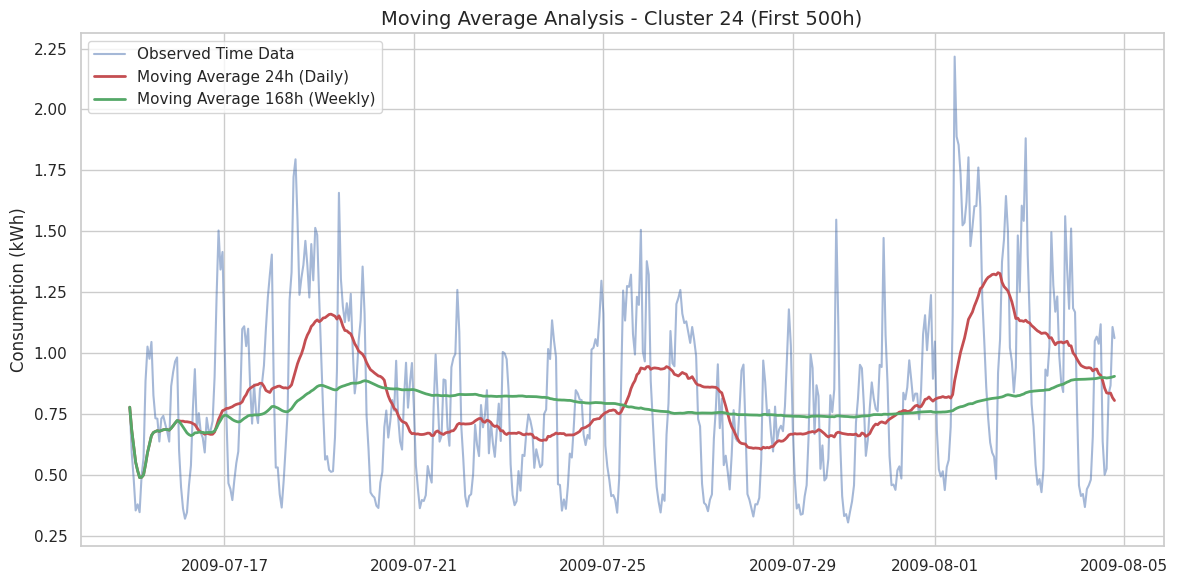

In [ ]:
plot_moving_averages(df = df, cluster = 'cluster_24')

Dal dato osservato i consumi energetici non presentano una grande variabilità, in quanto il minimo è di circa 0.25 kWh e il massimo è un picco isolato di 2.25 kWh. Non si riescono a cogliere pattern specifici, e ciò è dimostrato anche dall'irregolarità della curva relativa alla media mobile a 24h. I consumi, in questo caso, sono molto variabili e soggetti a picchi isolati.

### 1.4 Verifica Outliers

Tra i metodi illustrati in [questo articolo](https://www.statology.org/top-5-statistical-techniques-detect-handle-outliers-data/), applicheremo il metodo del Range Interquartile (IQR).

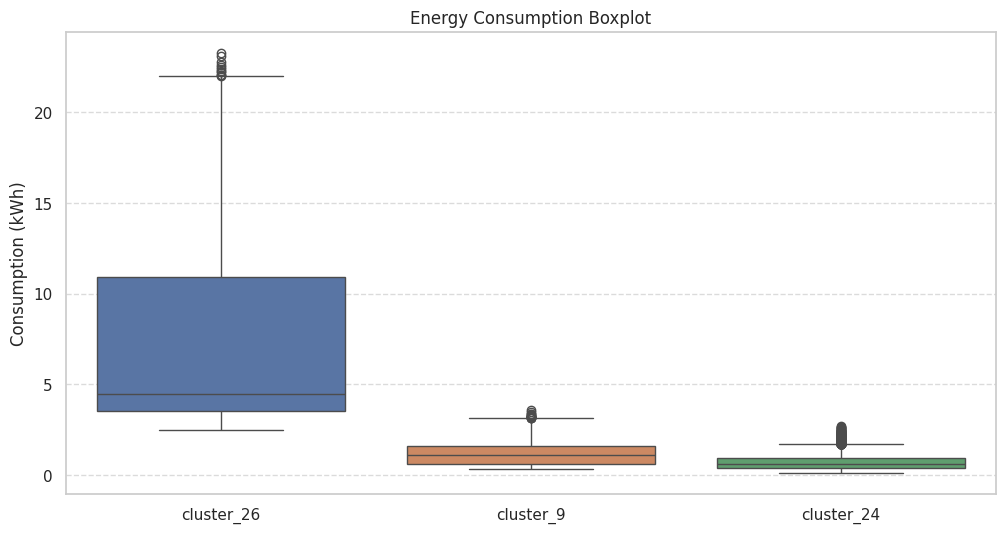

In [ ]:
plt.figure(figsize = (12, 6))
sns.boxplot(data = df)
plt.title('Energy Consumption Boxplot')
plt.ylabel('Consumption (kWh)')
plt.grid(axis = 'y', linestyle = '--', alpha = 0.7)
plt.savefig('cluster_boxplots.png');

Innanzitutto si nota come il box del cluster 26 sia posizionato molto più in alto lungo l'asse Y rispetto agli altri due, proprio perché i consumi rilevati in esso sono molto maggiori. Infatti, la mediana si attesta a circa 5 kWh, e l'ultimo quartile della distribuzione raggiunge consumi di oltre 20 kWh. Gli altri due cluster, invece, risultano più "schiacciati" poiché hanno una distribuzione molto più contenuta, con la mediana a meno di 2.5 kWh. Tra l'altro, la mediana del cluster 26 è molto più vicina alla linea del 1° quartile rispetto a quella del 3° quartile, e ciò significa che i valori tra il 25% e il 50% della distribuzione sono molto più concentrati rispetto a quelli tra il 50% e il 75% della distribuzione.

Inoltre, non solo la posizione, ma la dimensione stessa dei box, quindi il range interquartile, è estremamente diversa tra il cluster 26 e gli altri due cluster, indicando una volatilità nettamente maggiore nei consumi energetici.

Infine, si nota come in tutti e tre i cluster sia presente un alto numero di valori outlier, nella parte superiore della distribuzione. Ciò indica la presenza di numerosi picchi di consumo energetico.

In [ ]:
# Define a dictionary to store the outlier metrics
outlier_metrics_summary = {}

# Iterate on each cluster
for col in df.columns:

    # Quartiles
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    # Thresholds
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Filter for values below and above the thresholds
    current_col_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    percentage_outliers = (len(current_col_outliers) / len(df)) * 100

    # Store the metrics in the dictionary
    outlier_metrics_summary[col] = {
        'Q1': q1,
        'Q3': q3,
        'IQR': iqr,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Number of Outliers': len(current_col_outliers),
        'Percentage of Outliers': percentage_outliers,
        'Min Outlier': current_col_outliers[col].min() if len(current_col_outliers) > 0 else None,
        'Max Outlier': current_col_outliers[col].max() if len(current_col_outliers) > 0 else None
    }

# Print the results
print('--- Outlier Summary Statistics ---')
for i, k in outlier_metrics_summary.items():
    print(f'\n{i}:')
    for metric, val in k.items():
        print(f'  {metric}: {val:.4f}' if isinstance(val, float) else f'  {metric}: {val}')

# Top 3 value extraction
print('\n--- Top 3 Outliers by Cluster ---')
for col in df.columns:
    upper_bound = outlier_metrics_summary[col]['Upper Bound']
    outliers_df = df[df[col] > upper_bound]

    if len(outliers_df) > 0:
        print(f'\n{col} - Top 3 Maximum Values:')
        print(outliers_df[col].sort_values(ascending = False).head(3))

--- Outlier Summary Statistics ---

cluster_26:
  Q1: 3.5487
  Q3: 10.9234
  IQR: 7.3747
  Lower Bound: -7.5134
  Upper Bound: 21.9855
  Number of Outliers: 11
  Percentage of Outliers: 0.0857
  Min Outlier: 22.0083
  Max Outlier: 23.2739

cluster_9:
  Q1: 0.5888
  Q3: 1.6061
  IQR: 1.0173
  Lower Bound: -0.9371
  Upper Bound: 3.1321
  Number of Outliers: 15
  Percentage of Outliers: 0.1168
  Min Outlier: 3.1467
  Max Outlier: 3.5716

cluster_24:
  Q1: 0.4109
  Q3: 0.9212
  IQR: 0.5103
  Lower Bound: -0.3545
  Upper Bound: 1.6867
  Number of Outliers: 319
  Percentage of Outliers: 2.4844
  Min Outlier: 1.6878
  Max Outlier: 2.7111

--- Top 3 Outliers by Cluster ---

cluster_26 - Top 3 Maximum Values:
2010-12-20 11:00:00    23.273883
2010-12-20 10:00:00    23.101800
2010-12-22 11:00:00    22.729483
Name: cluster_26, dtype: float64

cluster_9 - Top 3 Maximum Values:
2009-12-25 14:00:00    3.571644
2009-12-25 13:00:00    3.452729
2009-12-25 12:00:00    3.379202
Name: cluster_9, dtype: flo

### 1.5 Feature Engineering

Generiamo alcune time-based features da aggiungere al dataset, in quanto sono utili per intercettare pattern periodici e stagionalità, come spiegato in [questo articolo](https://www.geeksforgeeks.org/data-analysis/feature-engineering-for-time-series-data-methods-and-applications/#example-2-timebased-features).

Per non rischiare problemi di collinearità, generiamo solamente le features relative al giorno della settimana e al mese.

In [ ]:
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month
df.head(10)

,cluster_26,cluster_9,cluster_24,day_of_week,month
2009-07-15 00:00:00,3.254085,1.037702,0.777450,2,7
2009-07-15 01:00:00,3.197561,0.730954,0.591275,2,7
2009-07-15 02:00:00,3.038390,0.518665,0.483900,2,7
2009-07-15 03:00:00,3.029756,0.423768,0.353325,2,7
2009-07-15 04:00:00,3.005634,0.382569,0.378625,2,7
2009-07-15 05:00:00,2.965024,0.382337,0.346350,2,7
2009-07-15 06:00:00,2.881841,0.393083,0.494350,2,7
2009-07-15 07:00:00,4.024280,0.478456,0.569550,2,7
2009-07-15 08:00:00,6.899854,0.606089,0.884900,2,7
2009-07-15 09:00:00,11.495024,0.769800,1.026325,2,7


### 1.6 Preparazione dei dati

Dividiamo il dataset in set di addestramento e di test, adottando lo split sequenziale 80%-20%.

In [ ]:
test_size = int(len(df) * .2)
train = df.iloc[:-test_size]
test = df.iloc[-test_size:]

print(f'Train Set: {len(train)} \nTest Set: {len(test)}')

Train Set: 10272 
Test Set: 2568


## 2. Previsione con modelli classici

### 2.1 Analisi ACF e PACF

Definiamo innanzitutto una funzione per rappresentare graficamente l'autocorrelazione (ACF) e l'autocorrelazione parziale (PACF), e identificare quindi i corretti ordini di autoregressione ($p$) e media mobile ($q$).

In [ ]:
def plot_acf_pacf(df, cluster, lags = 40, diff_lag = None):

    """
    This function plots and saves ACF and PACF for a given cluster.
    """

    # Extract time series and handle differentiation
    series = df[cluster]

    if diff_lag is not None:
        series = series.diff(diff_lag)
        title_suffix = f'Seasonal Diff (s = {diff_lag})'
        file_suffix = '_diff'
    else:
        title_suffix = 'Autocorrelation'
        file_suffix = ''

    # Remove NaN values
    series = series.dropna()

    # Plot ACF and PACF
    fig, axes = plt.subplots(1, 2, figsize = (14, 4))
    plot_acf(series, ax = axes[0], lags = lags)
    plot_pacf(series, ax = axes[1], lags = lags)

    # Set titles, labels, and layout
    axes[0].set_title(f'Autocorrelation (ACF) - {title_suffix}')
    axes[1].set_title(f'Partial Autocorrelation (PACF) - {title_suffix}')
    clean_title = cluster.replace('_', ' ').title()
    plt.suptitle(clean_title, fontsize = 14)
    plt.tight_layout()

    # Fix: Removed the tuple and called savefig correctly
    filename = f'acf_pacf_{cluster}{file_suffix}.png'
    plt.savefig(filename, bbox_inches = 'tight')
    plt.show()

Per il cluster 26, che presenta una stagionalità sia giornaliera (24 ore) che settimanale (168 ore), impostiamo i lag a 180.

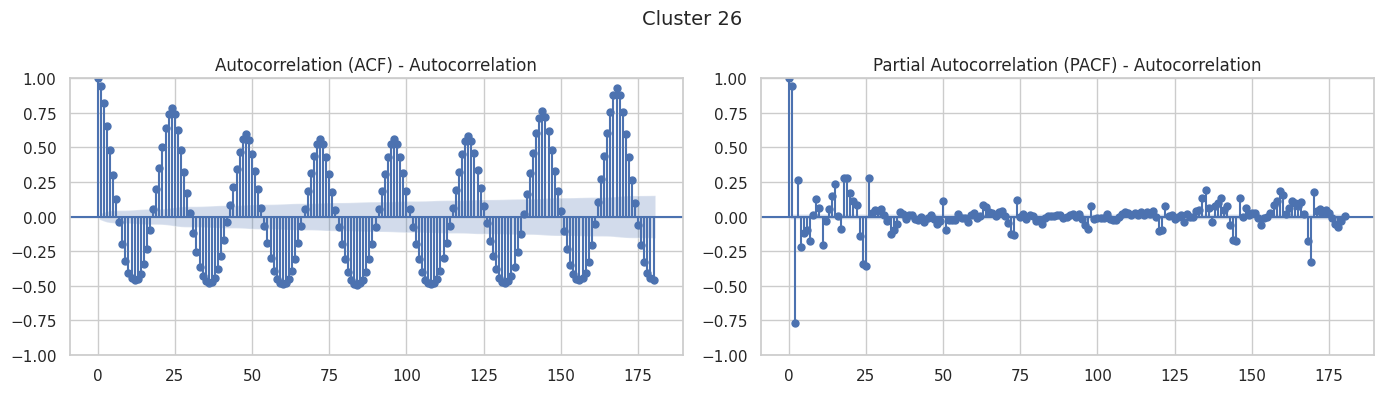

In [ ]:
plot_acf_pacf(df = train, cluster = 'cluster_26', lags = 180)

*   **ACF**: Si notano sia il pattern dovuto alla stagionalità giornaliera, caratterizzato da picchi ogni 24 ore, sia il pattern dovuto alla stagionalità settimanale, caratterizzato da un picco massimo in corrispondenza del lag 168.
*   **PACF**: Si nota un taglio netto in corrispondenza dei primi lag. Inoltre, dopo il lag 25 i valori diminuiscono ulteriormente.

Poiché né l'ACF né la PACF tendono a zero, sia il modello AR che il modello MA potrebbero funzionare. Inoltre, considerata la stagionalità sia giornaliera che settimanale, il modello più adatto è un SARIMA, con componente autoregressiva non stagionale $p=2$, componente autoregressiva stagionale $P=1$, differenziazione stagionale $D=1$, e periodo $s=168$.

Proviamo ad applicare una differenziazione settimanale e a rappresentare graficamente il risultato.

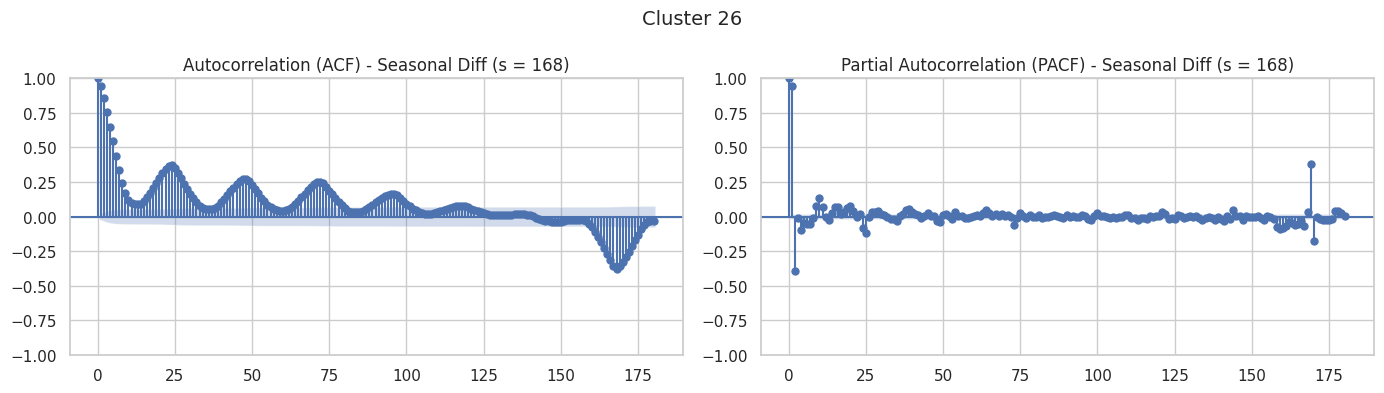

In [ ]:
plot_acf_pacf(df = train, cluster = 'cluster_26', lags = 180, diff_lag = 168)

*   **ACF**: La stagionalità settimanale è stata gestita, mentre la stagionalità giornaliera permane, ma con tendenza decadente all'avanzare dei lag. Rimane un picco negativo, seppur molto più contenuto di prima, in corrispondenza del lag 168.
*   **PACF**: Si nota ancora il taglio netto in corrispondenza dei primi lag, ma ora anche i valori successivi sono molto più vicini allo zero. Anche in questo grafico è presente un picco in corrispondenza del lag 168.

Ora analizziamo il cluster 9. Dato che presenta solamente una stagionalità giornaliera, impostiamo i lag a 40.

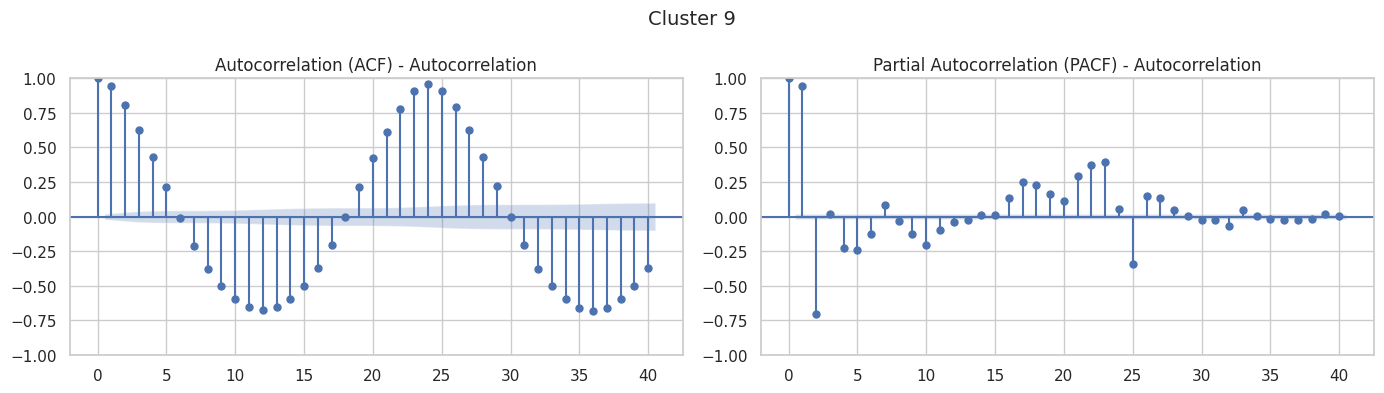

In [ ]:
plot_acf_pacf(df = train, cluster = 'cluster_9', lags = 40)

*   **ACF**: Si nota il pattern dovuto alla stagionalità giornaliera, costituito da picchi locali ogni 24 ore. Anche in questo caso, quindi, utilizzeremo un modello SARIMA e applicheremo una differenziazione stagionale.
*   **PACF**: In corrispondenza dei primi lag i valori sono molto simili al cluster 26, con un taglio netto dopo il lag 2. In questo caso, però, si nota anche un valore molto negativo isolato al lag 25.

Per questa serie, quindi, il modello più adatto risulta essere un SARIMA, con componente autoregressiva non stagionale $p=2$, componente autoregressiva stagionale $P=1$, differenziazione stagionale $D=1$ e periodo $s=24$.

Proviamo ad applicare una differenziazione giornaliera e a rappresentare graficamente il risultato.

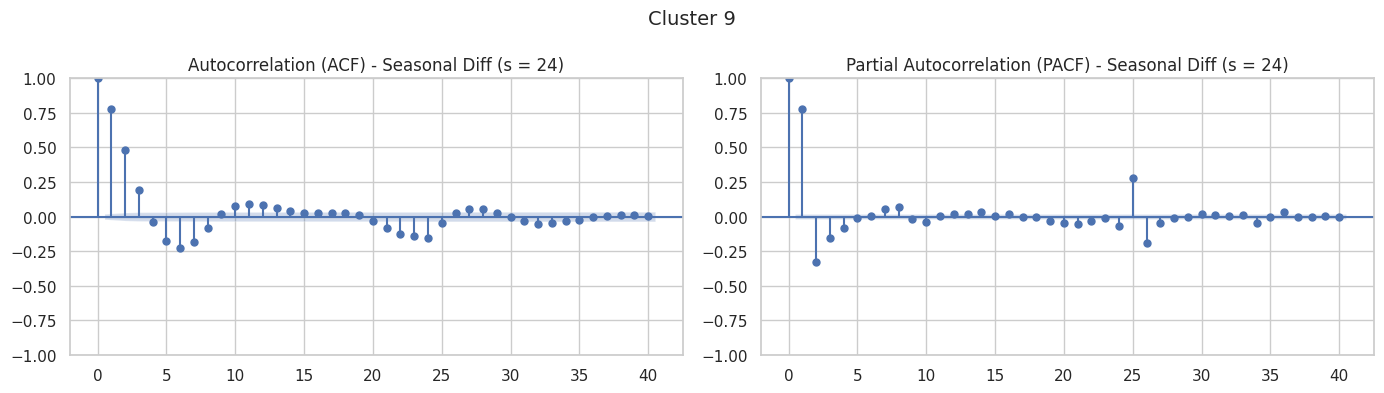

In [ ]:
plot_acf_pacf(df = train, cluster = 'cluster_9', lags = 40, diff_lag = 24)

*   **ACF**: L'onda con i picchi giornalieri è stata completamente gestita, e l'autocorrelazione tende verso lo zero già dopo i primi lag.
*   **PACF**: Ad eccezione di un picco al lag 25, i valori ora sono nettamente più bassi.

Infine, analizziamo il cluster 24. Dato che è privo di stagionalità, manteniamo un valore di lag pari a 40.

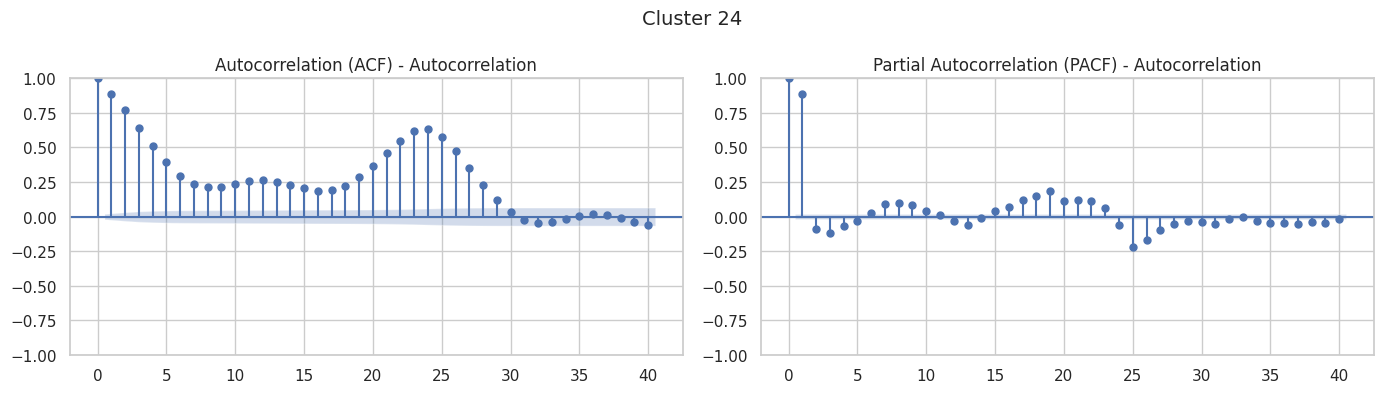

In [ ]:
plot_acf_pacf(df = train, cluster = 'cluster_24', lags = 40)

*   **ACF**: A differenza delle altre due serie, l'autocorrelazione in questo caso non segue un pattern ricorrente. Tuttavia, si nota un innalzamento positivo dei valori in corrispondenza del lag 24, che assomiglia a una stagionalità giornaliera.  
*   **PACF**: Si nota un taglio netto dopo il lag 1, indicando quindi che il modello adatto è un AR(1).

Per questa serie, quindi, un modello adatto potrebbe essere un ARIMA con solo la componente autoregressiva $p=1$, ma è possibile che sia necessario utilizzare un modello SARIMA, per intercettare l'innalzamento dell'autocorrelazione evidenziato al lag 24.

### 2.2 Addestramento del modello baseline AR(1) e dei modelli ARIMA e SARIMA

Innanzitutto, definiamo una funzione per calcolare le metriche di valutazione dei modelli, nonché un dizionario dove andremo ad inserirle.

In [ ]:
def evaluate_forecast(y_true, y_pred):

    """
    This function returns the MAE, RMSE, AND MAPE metrics for models.
    """

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return mae, rmse, mape

evaluation_metrics = {}

Ora passiamo all'addestramento del modello baseline AR(1) e dei modelli ARIMA e SARIMA. Per ottimizzare la scelta dei parametri, utilizzeremo una grid search che avrà come obiettivo quello di individuare i modelli con l'Akaike Information Criterion (AIC) minore.

In [ ]:
# Ignore the warning during the grid search
warnings.filterwarnings('ignore')


# Define grid search function
def grid_search(series, p_range, q_range, P_range, D_range, Q_range, d = 0, s = 24, verbosity = False):

    """
    This function applies a grid search, in order to select the model with the lowest AIC value
    """

    # Generate the parameter combinations
    pdq = list(itertools.product(p_range, [d], q_range))
    seasonal_pdq = list(itertools.product(P_range, D_range, Q_range, [s]))

    best_aic = float('inf')
    best_order = None
    best_seasonal_order = None

    if(verbosity): print(f'Start of Grid Search: {len(pdq) * len(seasonal_pdq)} total combinations.\n')

    for param in pdq:
        for param_seasonal in seasonal_pdq:
            if(verbosity): print(f'Evaluating for {param} and {param_seasonal}...')
            try:
                model = SARIMAX(series,
                                order = param,
                                seasonal_order = param_seasonal,
                                enforce_stationarity = False,
                                enforce_invertibility = False)

                results = model.fit(disp = False, maxiter = 20)

                # Save if AIC value is the new minimum
                if results.aic < best_aic:
                    best_aic = results.aic
                    best_order = param
                    best_seasonal_order = param_seasonal
                if(verbosity): print(f'Done evaluating. SUCCESS\n')
            except Exception:
                # If optimization fails, pass on to the new combination
                if(verbosity): print(f'Done evaluating. SKIP TO NEXT\n')
                continue

    return best_order, best_seasonal_order, best_aic


# Set up search range
p_range = q_range = range(0, 3)
P_range = Q_range = range(0, 2)
D_range = range(0, 2)


# Create a JSON file to store best parameters
PARAMS_FILE = 'best_sarima_params.json'

# Check if file exists. If it does, load the parameters
if os.path.exists(PARAMS_FILE):
    with open(PARAMS_FILE, 'r') as f:
        saved_params = json.load(f)
else:
    # Define an empty dictionary to store the parameters
    saved_params = {}



for col in df_clusters:
    print(f'Processing {col}...')
    local_train = train[col].dropna()
    local_test = test[col].dropna()

# Check if parameters for specific cluster already exist
    if col in saved_params:
        print(f'Pre-saved parameters found for {col}. Skipping Grid Search.')

        # Convert back JSON lists to tuples
        best_p = tuple(saved_params[col]['best_p'])
        best_P = tuple(saved_params[col]['best_P'])
        best_aic = saved_params[col]['best_aic']

    else:
        print(f'No pre-saved parameters found. Starting Grid Search for {col}...')

        # Define sub-train to search for best parameters
        local_search = local_train[-500:]

        # Start grid search
        best_p, best_P, best_aic = grid_search(local_search, p_range, q_range, P_range, D_range, Q_range)

        # Save new parameters in the dictionary
        saved_params[col] = {
            'best_p': best_p,
            'best_P': best_P,
            'best_aic': best_aic
            }

        # Overwrite JSON file
        with open(PARAMS_FILE, 'w') as f:
            json.dump(saved_params, f, indent = 4)


    print(f'Model found for {col}: {best_p} x {best_P} - AIC: {best_aic:.2f}\n')


    # Baseline AR(1) model
    baseline_model= ARIMA(local_train, order = (1, 0, 0))
    baseline_fit = baseline_model.fit()
    baseline_pred = baseline_fit.forecast(steps = len(local_test))

    # Get the forecast on the optimal model
    best_model = SARIMAX(local_train, order = best_p, seasonal_order = best_P)
    best_fit = best_model.fit(disp = False)
    cluster_pred = best_fit.forecast(steps = len(test[col].dropna()))

    # Save evaluation metrics in the result dictionary
    evaluation_metrics[col] = {'AR(1)': evaluate_forecast(local_test, baseline_pred),
                               'ARIMA/SARIMA': evaluate_forecast(local_test, cluster_pred)
                               }

Processing cluster_26...
No pre-saved parameters found. Starting Grid Search for cluster_26...
Model found for cluster_26: (2, 0, 2) x (0, 1, 1, 24) - AIC: 770.35

Processing cluster_9...
No pre-saved parameters found. Starting Grid Search for cluster_9...
Model found for cluster_9: (2, 0, 2) x (1, 0, 1, 24) - AIC: -1011.20

Processing cluster_24...
No pre-saved parameters found. Starting Grid Search for cluster_24...
Model found for cluster_24: (1, 0, 1) x (1, 0, 1, 24) - AIC: -430.97



La grid search, quindi, ha prodotto i seguenti risultati:

*   Modello per cluster 26: SARIMA(2, 0, 2) (0, 1, 1, 24), con AIC = 770.35.
*   Modello per cluster 9: SARIMA(2, 0, 2) (1, 0, 1, 24), con AIC = -1011.20.
*   Modello per cluster 24: SARIMA(1, 0, 1) (1, 0, 1, 24), con AIC = -430.97.

Pertanto, alla fine abbiamo applicato la differenziazione stagionale solamente sul cluster 26.

### 2.3 Valutazione delle previsioni

Mostriamo ora le metriche di valutazione raccolte, per confrontare i risultati dei modelli SARIMA con il modello baseline AR(1).

In [ ]:
metric_names = ['MAE', 'RMSE', 'MAPE (%)']

data = []
for cluster, models in evaluation_metrics.items():
    for model_name, metrics in models.items():
        row = {'Cluster': cluster,
               'Model': model_name,
               metric_names[0]: float(metrics[0]),
               metric_names[1]: float(metrics[1]),
               metric_names[2]: float(metrics[2])}
        data.append(row)


def highlight_best_model(df):

    """
    This function highlights the best model for each cluster, based on lowest MAE value
    """

    # Create an empty DataFrame
    style_df = pd.DataFrame('', index = df.index, columns = df.columns)

    for cluster in df['Cluster'].unique():

        # Find the minimum MAE
        idx_min = df[df['Cluster'] == cluster]['MAE'].idxmin()

        # Highlight the entire row
        style_df.loc[idx_min, :] = 'background-color: green; font-weight: bold'

    return style_df


df_evaluation_metrics = pd.DataFrame(data).round(2)
df_evaluation_metrics.style.apply(highlight_best_model, axis = None).format(subset = ['MAE', 'RMSE', 'MAPE (%)'], formatter = '{:.2f}')

,Cluster,Model,MAE,RMSE,MAPE (%)
0,cluster_26,AR(1),4.29,5.31,66.56
1,cluster_26,ARIMA/SARIMA,2.44,3.52,31.88
2,cluster_9,AR(1),0.59,0.70,65.62
3,cluster_9,ARIMA/SARIMA,0.24,0.38,15.99
4,cluster_24,AR(1),0.32,0.39,69.37
5,cluster_24,ARIMA/SARIMA,0.25,0.35,38.12


Si nota subito come, per tutte e tre le serie, il modello SARIMA abbia una performance migliore rispetto al modello baseline. In particolare:

*   **Cluster 26**: Il MAE scende da 4.29 a 2.44, il RMSE scende da 5.31 a 3.52, e l'errore percentuale passa dal 66.6% al 31.9%.
*   **Cluster 9**: Il MAE scende da 0.59 a 0.24, quindi viene più che dimezzato; il RMSE passa da 0.70 a 0.38, e l'errore percentuale crolla dal 65.6% al 16%.
*   **Cluster 24**: Il MAE e il RMSE scendono leggermente, passando da 0.32 a 0.25 e da 0.39 a 0.35, rispettivamente. L'errore percentuale invece cala drasticamente, passando dal 69,4% al 38,1%.

### 2.4 Confronto visivo tra valori predetti e valori reali sul set di test

Addestriamo i modelli scelti dalla grid search, per poi confrontare graficamente i valori predetti con i valori reali. Per velocizzare l'addestramento, utilizziamo una finestra temporale di circa tre mesi, quindi pari a 2400. Inoltre, introduciamo le variabili esogene *day_of_week* e *month*, per catturare meglio le variazioni temporali e, quindi, la stagionalità settimanale.

In [ ]:
def plot_sarima_forecast(cluster, train, test,
                         params_file = 'best_sarima_params.json', exog_cols = None,
                         tail_size = 2400, forecast_steps = 168, plot_tail = 350):

    """
    This function loads optimal parameters from JSON file, trains a SARIMA model,
    generates previsions, and plots and saves results.
    """

    # Load optimal parameters from JSON file
    if not os.path.exists(params_file):
        raise FileNotFoundError(f'Parameter file "{params_file}" not found. Please run the Grid Search.')

    with open(params_file, 'r') as f:
        saved_params = json.load(f)

    if cluster not in saved_params:
        raise KeyError(f'No parameters saved for "{cluster}" in "{params_file}".')

    # Convert back JSON lists to tuples
    best_p = tuple(saved_params[cluster]['best_p'])
    best_P = tuple(saved_params[cluster]['best_P'])

    print(f'--- {cluster.upper()} ---'
          f'\nLoaded parameters: order = {best_p} | seasonal_order = {best_P}')

    # Prepare data
    y_train = train[cluster].tail(tail_size)
    y_test = test[cluster].iloc[: forecast_steps]

    exog_train = train[exog_cols].tail(tail_size) if exog_cols else None
    exog_test = test[exog_cols].iloc[: forecast_steps] if exog_cols else None

    # Model fit
    print('Model fitting...\n')
    model = SARIMAX(y_train, exog = exog_train, order = best_p, seasonal_order = best_P)
    fit_result = model.fit()

    # Generate forecasts
    forecast = fit_result.get_forecast(steps = forecast_steps, exog = exog_test)
    pred_mean = forecast.predicted_mean

    # Plot results
    plt.figure(figsize = (12, 5))
    plt.plot(train[cluster].tail(plot_tail), label = f'Train Set (Last {plot_tail}h)', c = 'b')
    plt.plot(y_test, label = 'Test Set', c = 'g')
    plt.plot(pred_mean.index, pred_mean, label = 'SARIMA (Predicted)', c = 'r', linestyle = '--')
    suptitle_text = f'SARIMA {best_p} {best_P} Forecast ({forecast_steps}h)'
    plt.suptitle(suptitle_text, fontsize = 14)
    clean_title = cluster.replace('_', ' ').title()
    plt.title(clean_title, fontsize = 12)
    plt.ylabel('Consumption (kWh)')
    plt.legend(bbox_to_anchor = (1, 1), loc = 'upper left')
    plt.tight_layout()

    # Save plot
    cluster_num = cluster.replace('cluster_', '')
    filename = f'sarima_{cluster_num}_test_vs_pred.png'
    plt.savefig(filename, bbox_inches = 'tight')
    plt.show()

--- CLUSTER_26 ---
Loaded parameters: order = (2, 0, 2) | seasonal_order = (0, 1, 1, 24)
Model fitting...



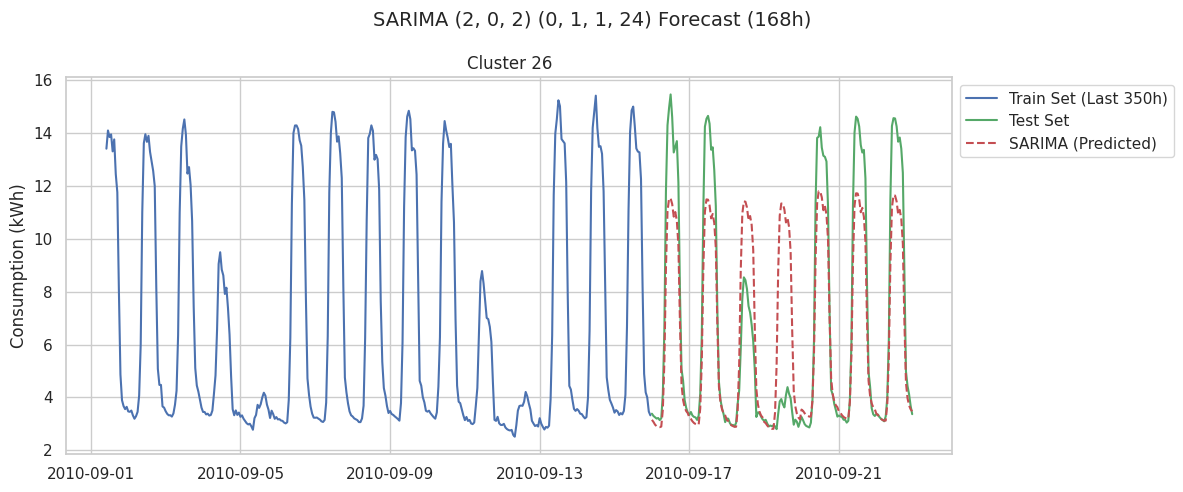

In [ ]:
exog_variables = ['day_of_week', 'month']
plot_sarima_forecast(cluster = 'cluster_26', train = train, test = test,
                     exog_cols = exog_variables)

Il modello ha intercettato correttamente la stagionalità giornaliera, come si evince dalla frequenza dei picchi, ma non è riuscito a cogliere la stagionalità settimanale, in quanto tutti i picchi della previsione hanno la stessa ampiezza, senza distinzione tra i giorni.

Per questo motivo, dovremmo addestrare il modello cambiando il parametro da $s=24$ a $s=168$. Tuttavia, a livello computazionale risulta troppo oneroso, quindi procederemo applicando un Exponential Smoothing e addestrando un modello Holt-Winters.

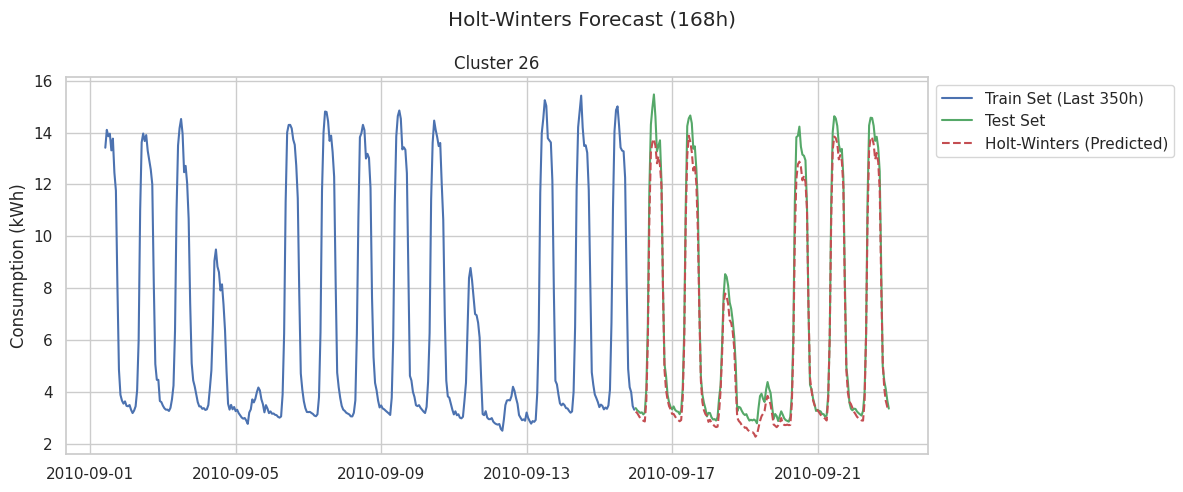

In [ ]:
# Model fit and forecast
hw_26_model = ExponentialSmoothing(train['cluster_26'].tail(2400),
                                   seasonal_periods = 168,
                                   trend = 'add',
                                   seasonal = 'add').fit()
hw_26_forecast = hw_26_model.forecast(168)

# Save evaluation metrics in dictionary
evaluation_metrics['cluster_26']['Holt-Winters'] = evaluate_forecast(test['cluster_26'].iloc[:168], hw_26_forecast)

# Plot data
plt.figure(figsize = (12, 5))
plt.plot(train['cluster_26'].tail(350), label = 'Train Set (Last 350h)', c = 'b')
plt.plot(test['cluster_26'].iloc[:168], label = 'Test Set', c = 'g')
plt.plot(hw_26_forecast.index, hw_26_forecast.values, label = 'Holt-Winters (Predicted)', c = 'r', linestyle = '--')
plt.suptitle('Holt-Winters Forecast (168h)')
plt.title('Cluster 26')
plt.ylabel('Consumption (kWh)')
plt.legend(bbox_to_anchor = (1, 1), loc = 'upper left')
plt.tight_layout()
plt.savefig('hw_26_test_vs_pred.png');

Il modello Holt-Winters riesce a cogliere la stagionalità sia giornaliera che settimanale, ritornando quindi una previsione molto più fedele ai valori reali.

--- CLUSTER_9 ---
Loaded parameters: order = (2, 0, 2) | seasonal_order = (1, 0, 1, 24)
Model fitting...



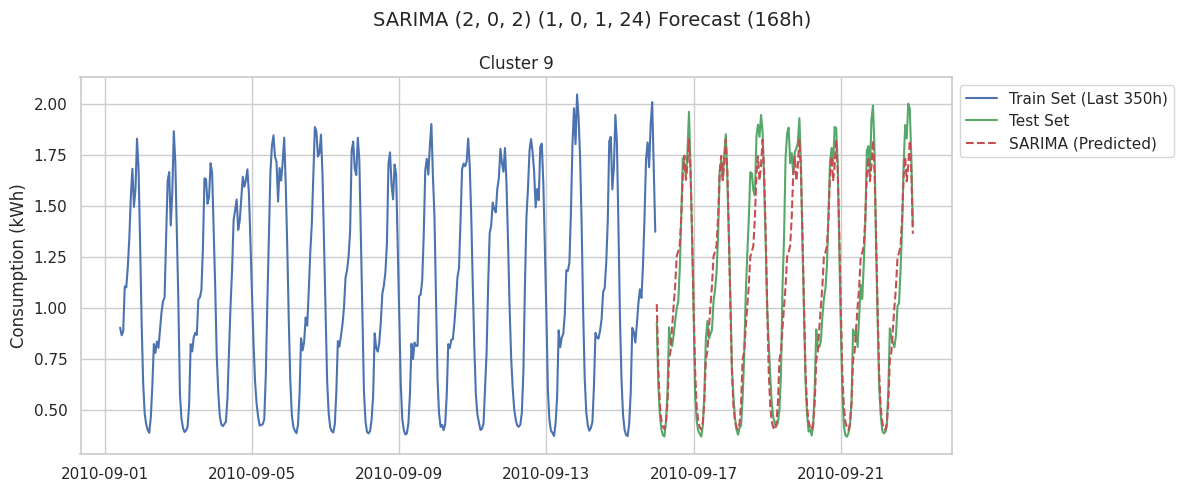

In [ ]:
plot_sarima_forecast(cluster = 'cluster_9', train = train, test = test)

Il modello è riuscito a cogliere la stagionalità giornaliera, ovvero l'unica presente in questa serie, e le previsioni risultano quindi abbastanza accurate.

--- CLUSTER_24 ---
Loaded parameters: order = (1, 0, 1) | seasonal_order = (1, 0, 1, 24)
Model fitting...



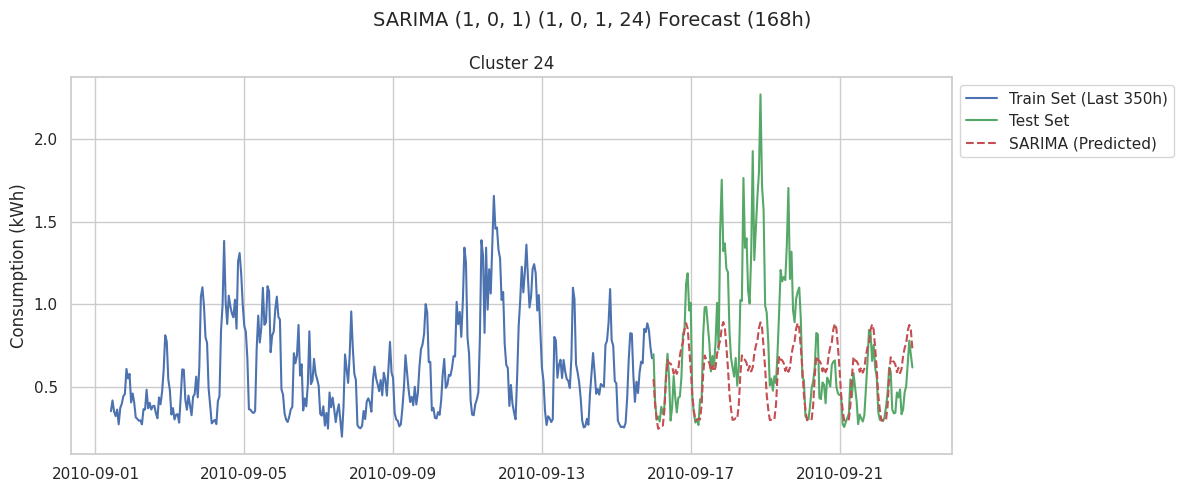

In [ ]:
plot_sarima_forecast(cluster = 'cluster_24', train = train, test = test)

Purtroppo, le previsioni del modello in questo caso differiscono molto rispetto ai valori reali. Proviamo quindi ad addestrare un modello Holt-Winters con Exponential Smoothing.

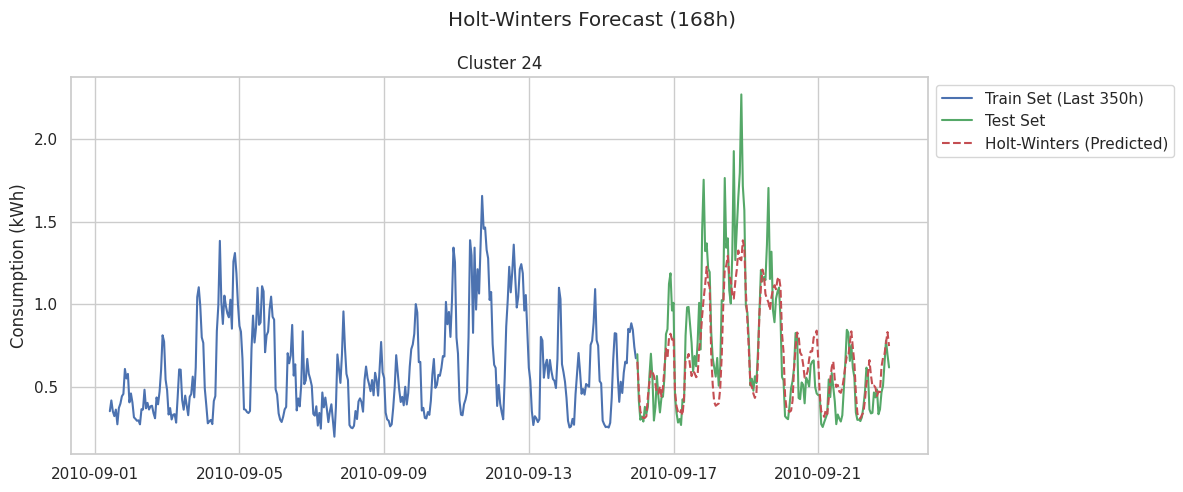

In [ ]:
# Model fit and forecast
hw_24_model = ExponentialSmoothing(train['cluster_24'].tail(2400),
                                   seasonal_periods = 168,
                                   trend = 'add',
                                   seasonal = 'add').fit()
hw_24_forecast = hw_24_model.forecast(168)

# Save evaluation metrics in dictionary
evaluation_metrics['cluster_24']['Holt-Winters'] = evaluate_forecast(test['cluster_24'].iloc[:168], hw_24_forecast)

# Plot data
plt.figure(figsize = (12, 5))
plt.plot(train['cluster_24'].tail(350), label = 'Train Set (Last 350h)', c = 'b')
plt.plot(test['cluster_24'].iloc[:168], label = 'Test Set', c = 'g')
plt.plot(hw_24_forecast.index, hw_24_forecast.values, label = 'Holt-Winters (Predicted)', c = 'r', linestyle = '--')
plt.suptitle('Holt-Winters Forecast (168h)')
plt.title('Cluster 24')
plt.ylabel('Consumption (kWh)')
plt.legend(bbox_to_anchor = (1, 1), loc = 'upper left')
plt.tight_layout()
plt.savefig('hw_24_test_vs_pred.png');

Si nota un miglioramento, ma la previsione rimane comunque non accurata.

## 3. Previsione con modelli ricorrenti

Passiamo ora alla previsione con modelli ricorrenti, in particolare con un modello LSTM. A tal fine, definiamo innanzitutto una funzione che costruisca le sequenze, le quali sono necessarie nel caso di reti neurali che gestiscono serie storiche.

In [ ]:
def create_sequences(data, window):

  """
  This function slices data into smaller sequences, based on a specific time window.
  """

  X, y = [], []
  for i in range(len(data) - window):
    X.append(data[i : (i + window), :])
    y.append(data[i + window, 0])
  return np.array(X), np.array(y)

Abbiamo già ottimizzato gli iperparametri dei modelli classici mediante l'implementazione di una grid search. Per ottimizzare gli iperparametri dei modelli ricorrenti, invece, implementeremo una Bayesian optimization con la libreria [**KerasTuner**](https://keras.io/keras_tuner/getting_started/).

Definiamo quindi una funzione, che ritornerà un modello Keras compilato. La funzione prende l'argomento **hp** per la definizione degli iperparametri durante la costruzione del modello.

In [ ]:
def build_model(hp):

    """
    This function defines the architecture of the recurrent model and the hyperparameter search space.
    """

    model = Sequential([
        Input(shape = (window_size, 1)),
        Conv1D(filters = hp.Int('conv_filters', min_value = 32, max_value = 128, step = 32),
               kernel_size = hp.Choice('conv_kernel', values = [3, 5, 7]),
               activation = 'relu',
               padding = 'same'),
        MaxPooling1D(pool_size = 2),

        LSTM(units = hp.Int('units_lstm_1', min_value = 64, max_value = 128, step = 32),
             return_sequences = True),
        Dropout(rate = hp.Float('dropout_rate', min_value = 0.2, max_value = 0.4, step = 0.1)),
        LSTM(units = hp.Int('units_lstm_2', min_value = 32, max_value = 64, step = 16)),
        Dense(1)
    ])

    # Define the optimizer learning rate as a hyperparameter
    learning_rate = hp.Float('learning_rate', min_value = 1e-4, max_value = 1e-2, sampling = 'log')

    model.compile(optimizer = Adam(learning_rate = learning_rate),
                  loss = 'mse',
                  metrics = ['mae'])
    return model

Procediamo ora con l'addestramento del modello LSTM sui tre cluster. Innanzitutto andiamo a definire la finestra temporale, dopodiché definiamo un ciclo in cui, per ciascuno dei tre cluster, effettueremo la suddivisione in set di addestramento e di test, normalizzeremo i dati, creeremo le sequenze mediante la funzione appena definita, addestreremo il modello e genereremo le previsioni.

In [ ]:
window_size = 168
test_size = int(len(df) * .2)

# Create a folder to save the models
os.makedirs('lstm_models', exist_ok = True)

# Training and tuning loop
for col in df_clusters:
    print(f'Starting process for {col}...')

    # Define paths to save data
    model_path = f'lstm_models/model_{col}.keras'
    scaler_path = f'lstm_models/scaler_{col}.pkl'

    # Reshape the target column
    ts_lstm = df[col].values.reshape(-1, 1)


    if os.path.exists(model_path) and os.path.exists(scaler_path):
        print(f'Pre-trained model found for {col}. Skipping the tuning.')

        # Load scaler and model
        scaler = joblib.load(scaler_path)
        lstm = load_model(model_path)

        # Prepare data for metrics
        local_test = ts_lstm[-(test_size + window_size):]
        local_test_scaled = scaler.transform(local_test)
        X_test, y_test = create_sequences(local_test_scaled, window = window_size)

        # Generate predictions and save metrics
        y_pred_scaled = lstm.predict(X_test, verbose = 0)
        predictions = scaler.inverse_transform(y_pred_scaled)
        actuals = scaler.inverse_transform(y_test.reshape(-1, 1))

        evaluation_metrics[col]['LSTM'] = evaluate_forecast(actuals, predictions)
        print(f'Metrics successfully calculated.\n')

        continue

    print(f'No saves found. Starting hyperparameter tuning & training for {col}...')


    # Keep last 2400 hours in train set to speed up the training
    local_train_full = ts_lstm[:-test_size]
    local_train = local_train_full[-2400:]
    local_test = ts_lstm[-(test_size + window_size):]

    # Normalize the data
    scaler = MinMaxScaler()
    local_train_scaled = scaler.fit_transform(local_train)
    local_test_scaled = scaler.transform(local_test)
    joblib.dump(scaler, scaler_path)

    # Create sequences
    X_train, y_train = create_sequences(local_train_scaled, window = window_size)
    X_test, y_test = create_sequences(local_test_scaled, window = window_size)

    # Initialise the tuner
    tuner = kt.BayesianOptimization(
        hypermodel = build_model,
        objective = 'val_loss',
        max_trials = 5,
        executions_per_trial = 3,
        directory = f'kt_tuning_{col}',
        project_name = 'lstm_bounds',
        overwrite = False
        )

    early_stop_tuning = EarlyStopping(monitor = 'val_loss', patience = 5, restore_best_weights = True)

    # Start Bayesian optimization
    print(f'Running Bayesian Optimization for {col}...')
    tuner.search(X_train, y_train, epochs = 5, batch_size = 512, validation_split = .1,
                callbacks = [early_stop_tuning], verbose = 0)

    # Extract optimal model
    best_hps = tuner.get_best_hyperparameters(num_trials = 1)[0]
    print(f'\nBest Hyperparameters for {col}:')
    print(f' - CNN Filters: {best_hps.get("conv_filters")}')
    print(f' - CNN Kernel: {best_hps.get("conv_kernel")}')
    print(f' - LSTM 1 Units: {best_hps.get("units_lstm_1")}')
    print(f' - Dropout Rate: {best_hps.get("dropout_rate")}')
    print(f' - LSTM 2 Units: {best_hps.get("units_lstm_2")}')
    print(f' - Learning Rate: {best_hps.get("learning_rate"):.4f}')

    # Final model fit
    lstm = tuner.hypermodel.build(best_hps)
    early_stop_final = EarlyStopping(patience = 8, restore_best_weights = True)

    lstm.fit(X_train, y_train, epochs = 15, batch_size = 512, validation_split = .1,
            callbacks = [early_stop_final], verbose = 0)

    # Save the model
    lstm.save(model_path)

    # Generate predictions
    y_pred_scaled = lstm.predict(X_test, verbose = 0)
    predictions = scaler.inverse_transform(y_pred_scaled)
    actuals = scaler.inverse_transform(y_test.reshape(-1, 1))

    # Save evaluation metrics
    evaluation_metrics[col]['LSTM'] = evaluate_forecast(actuals, predictions)

    print(f'Tuning and training completed for {col}\n')

Starting process for cluster_26...
No saves found. Starting hyperparameter tuning & training for cluster_26...
Running Bayesian Optimization for cluster_26...

Best Hyperparameters for cluster_26:
 - CNN Filters: 32
 - CNN Kernel: 7
 - LSTM 1 Units: 64
 - Dropout Rate: 0.2
 - LSTM 2 Units: 64
 - Learning Rate: 0.0058
Tuning and training completed for cluster_26

Starting process for cluster_9...
No saves found. Starting hyperparameter tuning & training for cluster_9...
Running Bayesian Optimization for cluster_9...

Best Hyperparameters for cluster_9:
 - CNN Filters: 96
 - CNN Kernel: 7
 - LSTM 1 Units: 64
 - Dropout Rate: 0.4
 - LSTM 2 Units: 32
 - Learning Rate: 0.0075
Tuning and training completed for cluster_9

Starting process for cluster_24...
No saves found. Starting hyperparameter tuning & training for cluster_24...
Running Bayesian Optimization for cluster_24...

Best Hyperparameters for cluster_24:
 - CNN Filters: 96
 - CNN Kernel: 3
 - LSTM 1 Units: 64
 - Dropout Rate: 0.4
 

Ora che abbiamo selezionato e salvato il modello ottimale per ciascun cluster, definiamo una funzione che carichi i modelli ottimali, esegua l'addestramento e calcoli le previsioni per la rappresentazione grafica.

In [ ]:
def plot_lstm_forecast(df, cluster, train, test, window_size, test_size):

    """
    Ths function loads the model and scaler for a specific cluster,
    generates the predictions and plots the results.
    """

    # Extract cluster number for titles and to save files
    cluster_num = cluster.split('_')[1]

    # Prepare data
    ts_lstm = df[cluster].values.reshape(-1, 1)
    test_lstm = ts_lstm[-(test_size + window_size):]

    # Load scaler and model
    scaler = joblib.load(f'lstm_models/scaler_{cluster}.pkl')
    lstm_model = load_model(f'lstm_models/model_{cluster}.keras')

    # Transform data and create sequences
    test_lstm_scaled = scaler.transform(test_lstm)
    X_test, _ = create_sequences(test_lstm_scaled, window = window_size)

    # Generate predictions and inverse transform data
    y_pred_scaled = lstm_model.predict(X_test, verbose = 0)
    predictions = scaler.inverse_transform(y_pred_scaled)

    # Plot results
    plt.figure(figsize = (12, 5))
    plt.plot(train[cluster].tail(350), label = 'Train Set (Last 350h)', c = 'b')
    plt.plot(test[cluster].iloc[:168], label = 'Test Set', c = 'g')
    plt.plot(test[cluster].iloc[:168].index, predictions[:168],
             label = 'LSTM Predictions', c = 'r', linestyle = '--')

    plt.suptitle('LSTM Forecast (168h)', fontsize = 14)
    plt.title(f'Cluster {cluster_num}')
    plt.ylabel('Consumption (kWh)')
    plt.legend(bbox_to_anchor = (1, 1), loc = 'upper left')

    # Save plots
    plt.tight_layout()
    plt.savefig(f'lstm_{cluster_num}_test_vs_pred.png')
    plt.show()

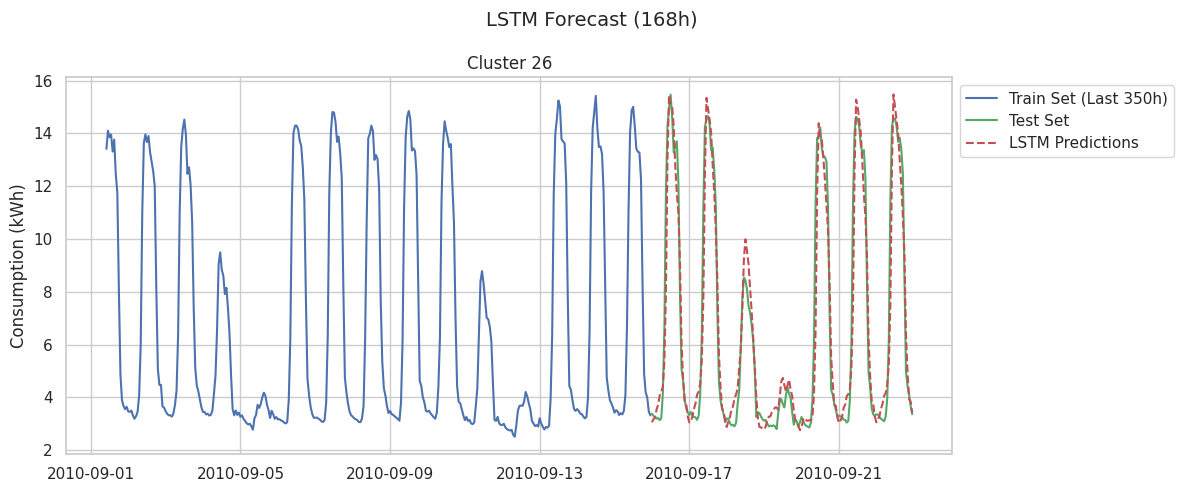

In [ ]:
plot_lstm_forecast(df = df, cluster = 'cluster_26', train = train,
                   test = test, window_size = window_size, test_size = test_size)

Le previsioni eseguite con il modello LSTM ricalcano molto bene la frequenza delle fluttuazioni, ma tende a sovrastimare i picchi. Nel complesso, però, il modello risulta accurato.

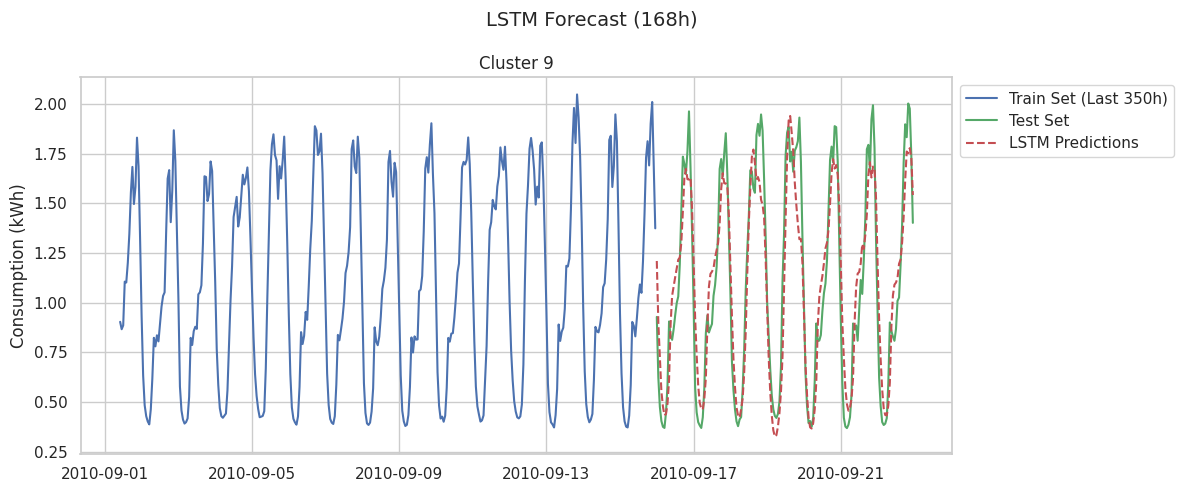

In [ ]:
plot_lstm_forecast(df = df, cluster = 'cluster_9', train = train,
                   test = test, window_size = window_size, test_size = test_size)

Nel caso di questo secondo cluster, le previsioni riescono a cogliere la frequenza delle fluttuazioni, ma tendono a sottostimare i picchi di consumo energetico massimi. Inoltre, i picchi minimi vengono previsti come più bassi di quelli effettivi.

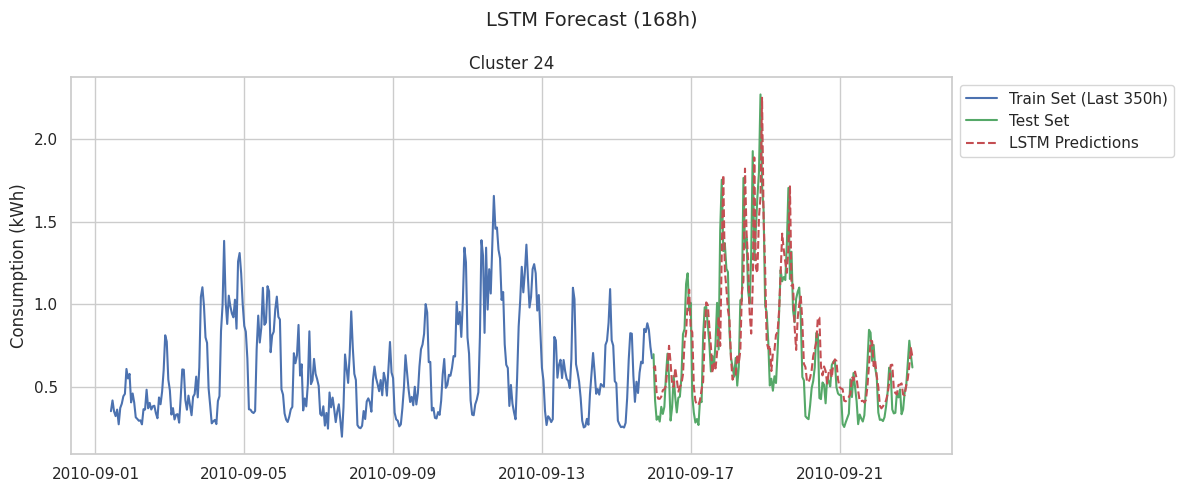

In [ ]:
plot_lstm_forecast(df = df, cluster = 'cluster_24', train = train,
                   test = test, window_size = window_size, test_size = test_size)

Nel caso di quest'ultimo cluster, il modello coglie solo a grandi linee la frequenza delle fluttuazioni, ma non riesce a catturare l'ampiezza e il dettaglio dati dalla volatilità dei consumi, quindi la previsione non risulta sufficientemente accurata.

## 4. Confronto delle performance

### 4.1 Visualizzazione e confronto delle metriche

Visualizziamo in una tabella le diverse performance dei modelli classici e i modelli ricorrenti, sulla base delle metriche prese in esame.

In [ ]:
data = []
for cluster, model in evaluation_metrics.items():
    for model_name, metrics in model.items():
        row = {'Cluster': cluster,
               'Model': model_name,
               'MAE': float(metrics[0]),
               'RMSE': float(metrics[1]),
               'MAPE (%)': float(metrics[2])}
        data.append(row)

df_evaluation_metrics = pd.DataFrame(data).round(2)
df_evaluation_metrics.style.apply(highlight_best_model, axis = None).format(subset = ['MAE', 'RMSE', 'MAPE (%)'], formatter = '{:.2f}')

,Cluster,Model,MAE,RMSE,MAPE (%)
0,cluster_26,AR(1),4.29,5.31,66.56
1,cluster_26,ARIMA/SARIMA,2.44,3.52,31.88
2,cluster_26,Holt-Winters,0.45,0.56,7.66
3,cluster_26,LSTM,0.93,1.44,12.44
4,cluster_9,AR(1),0.59,0.70,65.62
5,cluster_9,ARIMA/SARIMA,0.24,0.38,15.99
6,cluster_9,LSTM,0.22,0.30,18.86
7,cluster_24,AR(1),0.32,0.39,69.37
8,cluster_24,ARIMA/SARIMA,0.25,0.35,38.12
9,cluster_24,Holt-Winters,0.15,0.21,21.59


Dal confronto delle metriche emerge quanto segue.

Per il **cluster 26** e il **cluster 24**, la performance migliore risulta essere quella del modello Holt-Winters, con tutte e tre le metriche nettamente migliori rispetto agli altri modelli.

Per il **cluster 9**, invece, la situazione è più complessa poiché il modello LSTM ottiene delle performance migliori in termini di RMSE, mentre il modello SARIMA performa meglio in termini di MAPE, a quasi parità di MAE tra i due modelli. Poiché l'RMSE penalizza maggiormente gli errori più grandi, l'implicazione potrebbe essere che il modello SARIMA commetta degli errori di previsione maggiori sui picchi. Invece un valore alto del MAPE, che calcola l'errore percentuale rispetto al valore reale, implica possibilmente la presenza di errori di previsione, anche piccoli, sui valori più bassi della serie.

Con queste premesse, considerato che l'obiettivo dell'analisi è la stima del consumo di energia elettrica in un'ottica di miglioramento nell'approvvigionamento, l'aspetto più importante è garantire la disponibilità di energia nei momenti di picco dei consumi, evitando quindi che si verifichino blackout e interruzioni della fornitura. Poiché, come detto sopra, il modello SARIMA performa peggio in termini di RMSE, il modello da preferire in questo caso specifico è LSTM.

### 4.2 Diagnostica sui residui per omoschedasticità, normalità e autocorrelazione

Definiamo una funzione, che genererà i grafici relativi ai residui per ciascuno dei tre cluster, in modo da poterne eseguire la diagnostica.

In [ ]:
def plot_residuals(residuals, title_suffix):

  """
  This function plots the model's residuals
  """

  # Drop any NaN values
  residuals = residuals.dropna()

  fig = plt.figure(figsize = (14, 8))

  # 1. Time Series Chart
  ax1 = plt.subplot(2, 2, (1, 2))
  ax1.plot(residuals.index, residuals, c = 'b')
  ax1.axhline(0, c = 'r', linestyle = '--')
  ax1.set_title(f'Residuals over time ({title_suffix})', fontsize = 14)
  ax1.set_xlabel('Date')
  ax1.set_ylabel('Residuals')

  # 2. Histogram
  ax2 = plt.subplot(2, 2, 3)
  ax2.hist(residuals, bins = 20, edgecolor = 'k', alpha = .7, color = 'b')
  ax2.set_title(f'Residuals Histogram ({title_suffix})', fontsize = 14)
  ax2.set_xlabel('Residuals')
  ax2.set_ylabel('Frequency')

  # 3. Autocorrelation (ACF)
  ax3 = plt.subplot(2, 2, 4)
  plot_acf(residuals, lags = 500, ax = ax3)
  ax3.set_title(f'Autocorrelation (ACF) ({title_suffix})', fontsize = 14)
  ax3.set_xlabel('Lag')
  ax3.set_ylabel('Autocorrelation')

  # Adjust layout
  plt.tight_layout()

  # Save graphs for each cluster
  filename = f'diagnostics_{title_suffix.replace(" ", "_").lower()}.png'
  plt.savefig(filename)
  plt.show()

Poiché i modelli ricorrenti, a differenza dei modelli classici, non hanno un metodo .resid per poter ricavare i residui, definiamo un'altra funzione che ci permetta di ottenerli.

In [ ]:
def get_lstm_residuals(df, cluster, test, window_size, test_size):

    """
    This function the LSTM model, generates predictions for the entire test set,
    and returns the model's residuals.
    """

    # Load scaler and model
    scaler = joblib.load(f'lstm_models/scaler_{cluster}.pkl')
    lstm_model = load_model(f'lstm_models/model_{cluster}.keras')

    # Prepare data
    ts_lstm = df[cluster].values.reshape(-1, 1)
    test_lstm = ts_lstm[-(test_size + window_size):]
    test_lstm_scaled = scaler.transform(test_lstm)
    X_test, _ = create_sequences(test_lstm_scaled, window = window_size)

    # Predict and inverse transform
    y_pred_scaled = lstm_model.predict(X_test, verbose = 0)
    predictions = scaler.inverse_transform(y_pred_scaled).flatten()

    # Extract actual values
    actuals = test[cluster].values

    # Calculate and return residuals
    residuals_series = pd.Series((actuals - predictions), index = test.index)

    return residuals_series

Inoltre, definiamo una funzione che esegua il test di Ljung-Box, per verificare la presenza o meno di autocorrelazione tra i residui.

In [ ]:
def ljungbox_test(residuals):
  lb_test = acorr_ljungbox(pd.Series(residuals).dropna(), lags = [24, 168], return_df = True)
  lb_test['Result'] = ['No Autocorrelation' if p >= 0.05 else 'Autocorrelation' for p in lb_test['lb_pvalue']]

  return lb_test[['lb_pvalue', 'Result']].rename(columns = {'lb_pvalue': 'p-value'})

### Cluster 26

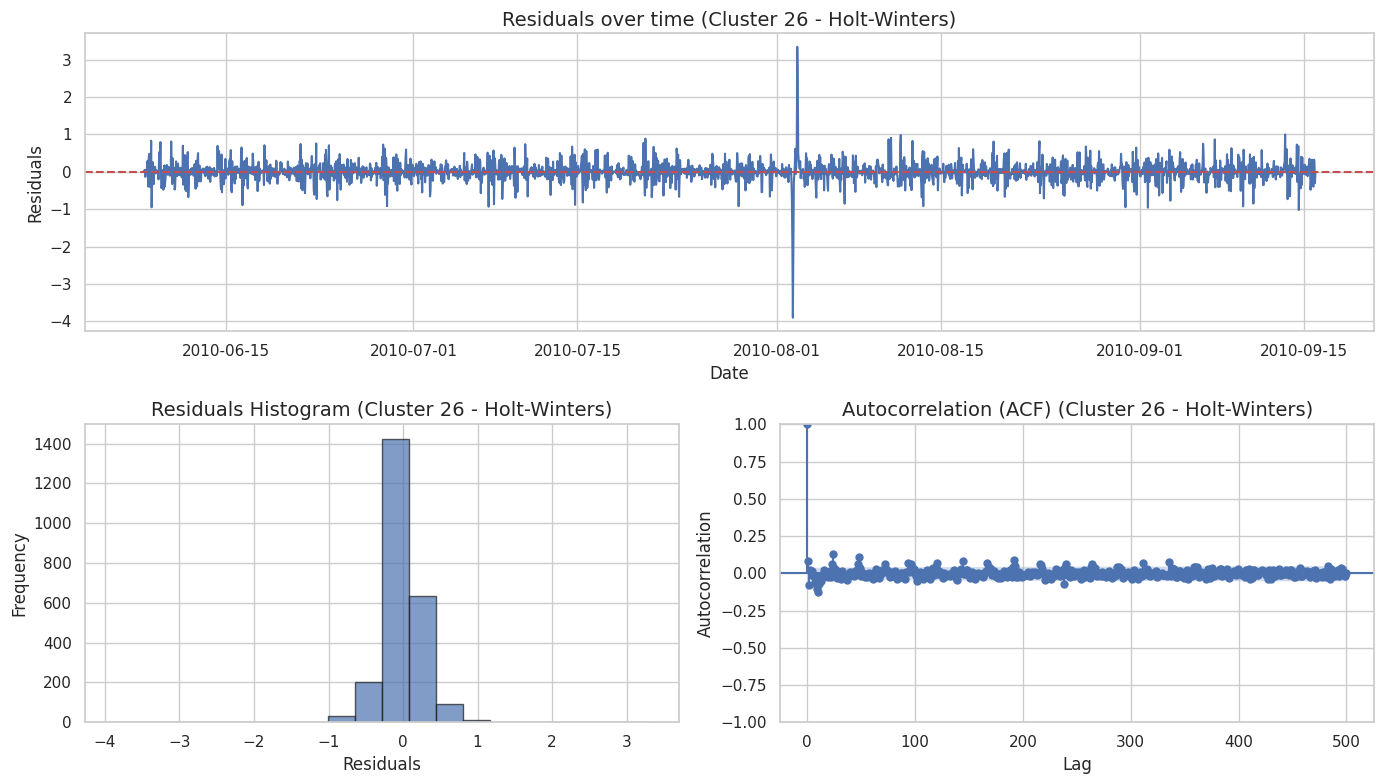

In [ ]:
plot_residuals(hw_26_model.resid, title_suffix = 'Cluster 26 - Holt-Winters')

Dai tre grafici si osserva un comportamento abbastanza soddisfacente dei residui, con un'unica eccezione nel primo grafico. Infatti, si nota come nella maggior parte del tempo i residui siano concentrati attorno allo zero, mentre, a inizio agosto 2010, ci sia stato un picco negativo e poi un picco positivo di ampiezza quasi identica. Questo valore outlier è da imputarsi probabilmente a un evento estremo, che il modello non ha saputo cogliere.

Per quanto riguarda l'istogramma, la distribuzione è correttamente centrata sullo zero e la forma è abbastanza a campana, ma è fortemente leptocurtica, ovvero molto più allungata rispetto a una normale.

Infine, in merito all'ultimo grafico, ad esclusione del primissimo lag non si notano livelli significativi di autocorrelazione tra i residui.

Nel complesso, quindi, si può dire che il modello ha colto bene il trend e la stagionalità della serie storica.

In [ ]:
ljungbox_test(hw_26_model.resid)

,p-value,Result
24,6.088868e-31,Autocorrelation
168,1.642294e-29,Autocorrelation


Sebbene i grafici mostrino dei risultati abbastanza buoni, il test Ljung-Box rivela comunque la presenza di autocorrelazione tra i residui.

### Cluster 9

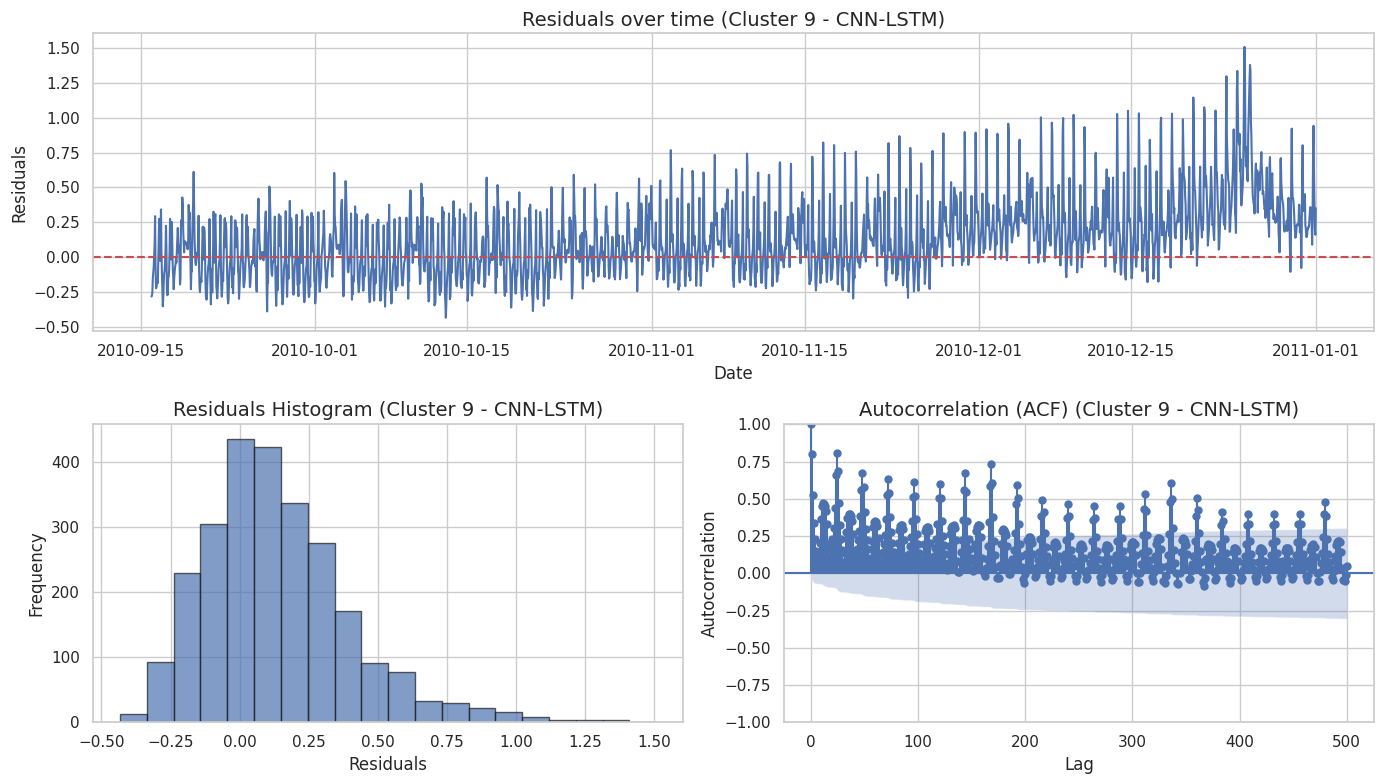

In [ ]:
residuals_9 = get_lstm_residuals(df = df, cluster = 'cluster_9', test = test,
                                  window_size = window_size, test_size = test_size)
plot_residuals(residuals_9, title_suffix = 'Cluster 9 - CNN-LSTM')

In questo caso, i grafici mostrano un comportamento dei residui molto problematico, che ci lascia intendere che il modello non è riuscito a catturare alcuni aspetti importanti della serie storica.

Nel grafico temporale, infatti, si nota un trend crescente nei residui, nonché un incremento dell'ampiezza. In altre parole, le previsioni del modello peggiorano col passare del tempo.

Dall'istogramma, invece, si nota una distribuzione asimmetrica con la coda verso destra, e ciò significa che il modello tende a restituire residui troppo alti, e quindi a sottostimare le previsioni sui valori reali.

Infine, l'ultimo grafico mostra un'evidente autocorrelazione positiva tra i residui, ben oltre l'intervallo di confidenza. Proveremo a gestire la problematica.

### Cluster 24

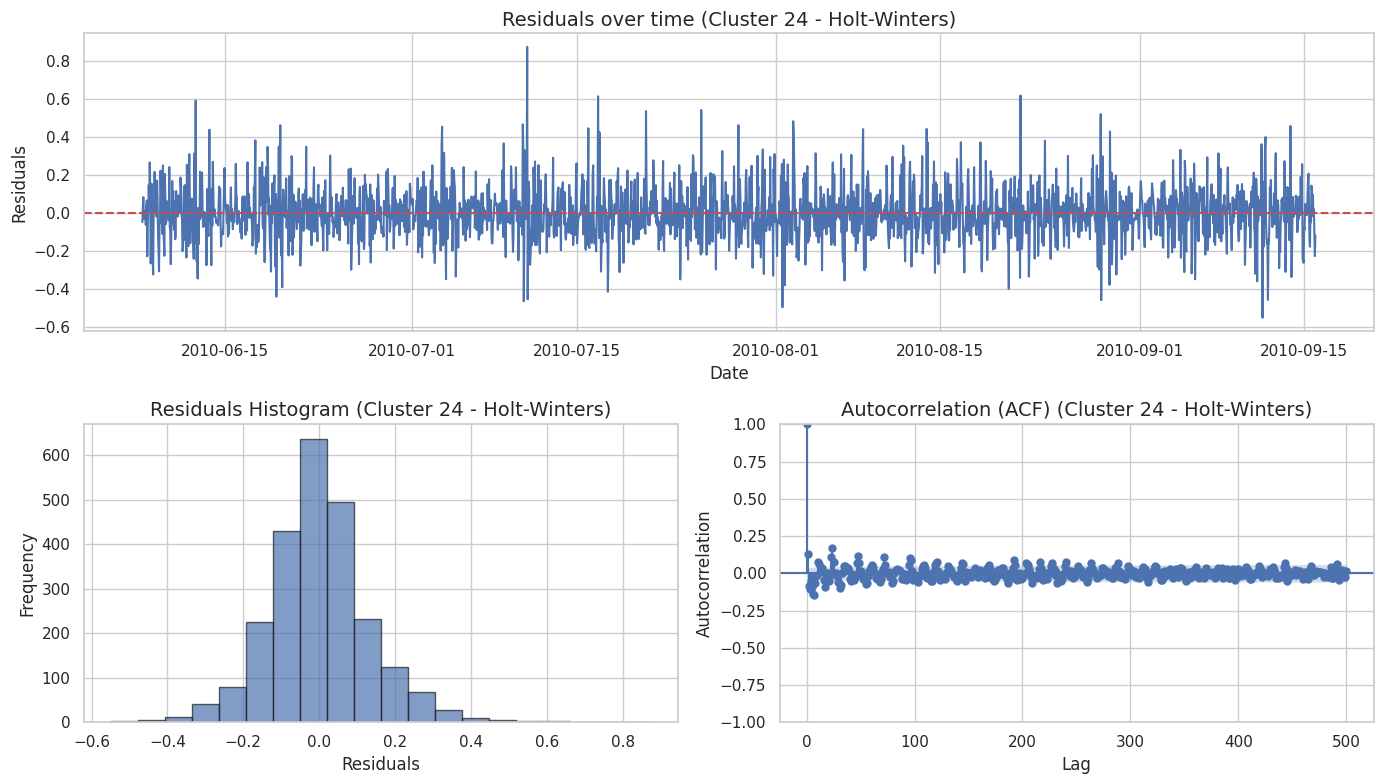

In [ ]:
plot_residuals(hw_24_model.resid, title_suffix = 'Cluster 24 - Holt-Winters')

In tutti e tre i grafici si può notare che il modello ha catturato molto bene la struttura della serie storica. Infatti, nel primo grafico gli errori oscillano in maniera abbastanza casuale attorno allo zero, pertanto si possono definire omoschedastici. Inoltre, nell'istogramma si osserva una distribuzione simmetrica e a campana, nonché centrata sullo zero, quindi gli errori risultano distribuiti normalmente. Infine, nell'ultimo grafico relativo all'autocorrelazione, gli errori convergono all'interno della fascia di confidenza (ad eccezione del primissimo lag), indicando assenza di autocorrelazione.

In [ ]:
ljungbox_test(hw_24_model.resid)

,p-value,Result
24,2.211581e-67,Autocorrelation
168,1.620431e-110,Autocorrelation


Anche in questo caso, nonostante i buoni risultati nei grafici, il test Ljung-Box evidenzia la presenza di autocorrelazione tra i residui.

Recuperiamo ora gli iperparametri che erano stati salvati per il modello LSTM sul cluster 9, per andare ad apportare alcune modifiche alla struttura e riaddestrare il modello, nel tentativo di risolvere le problematiche emerse durante la diagnostica dei residui.

In [ ]:
# Load tuner and previous hyperparameters
tuner_9 = kt.BayesianOptimization(hypermodel = build_model,
                                  objective = 'val_loss',
                                  directory = 'kt_tuning_cluster_9',
                                  project_name ='lstm_bounds')

best_hparams_9 = tuner_9.get_best_hyperparameters(num_trials = 1)[0]

print('--- Hyperparameters loaded for Cluster 9 ---\n'
      f'CNN Filters: {best_hparams_9.get("conv_filters")}\n'
      f'CNN Kernel: {best_hparams_9.get("conv_kernel")}\n'
      f'LSTM 1 Units: {best_hparams_9.get("units_lstm_1")}\n'
      f'LSTM 2 Units: {best_hparams_9.get("units_lstm_2")}\n'
      f'Dropout Rate: {best_hparams_9.get("dropout_rate")}\n'
      f'Learning Rate: {best_hparams_9.get("learning_rate"):.4f}')


# Extract exogenous variables
df['hour'] = df.index.hour
df['day_of_week'] = df.index.dayofweek
df['month'] = df.index.month


# Prepare data
features = ['cluster_9', 'hour', 'day_of_week', 'month']
data = df[features].values
window_size = 168

scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)


# Create sequences
X, y = [], []
for i in range(window_size, len(data_scaled)):
    X.append(data_scaled[i - window_size : i, :])
    y.append(data_scaled[i, 0])

X, y = np.array(X), np.array(y)


# Split data in train and test set
threshold = int(len(X) * 0.8)
X_train, X_test = X[: threshold], X[threshold :]
y_train, y_test = y[: threshold], y[threshold :]


# Build model
model_9_new = Sequential([
    Input(shape = (window_size, len(features))),
    Conv1D(filters = best_hparams_9.get('conv_filters'),
           kernel_size = best_hparams_9.get('conv_kernel'),
           activation = 'relu',
           padding = 'same'),
    MaxPooling1D(pool_size = 2),
    LSTM(units = best_hparams_9.get('units_lstm_1'), return_sequences = True),
    Dropout(rate = best_hparams_9.get('dropout_rate')),
    LSTM(units = best_hparams_9.get('units_lstm_2')),
    Dense(1)
])

model_9_new.compile(optimizer = Adam(learning_rate = best_hparams_9.get('learning_rate')),
                    loss = 'mse')


# Fit model
print('Start model fitting...\n')
early_stop = EarlyStopping(patience = 5, restore_best_weights = True)
model_9_new.fit(X_train, y_train, epochs = 20,
                batch_size = 64, validation_data = (X_test, y_test),
                callbacks = [early_stop], verbose = 0)


# Save new model
model_9_new.save('lstm_models/cluster_9_new.keras')
joblib.dump(scaler, 'lstm_models/cluster_9_new.pkl')
print('New version of the model successfully saved.\n')

Reloading Tuner from kt_tuning_cluster_9/lstm_bounds/tuner0.json
--- Hyperparameters loaded for Cluster 9 ---
CNN Filters: 96
CNN Kernel: 7
LSTM 1 Units: 64
LSTM 2 Units: 32
Dropout Rate: 0.4
Learning Rate: 0.0075
Start model fitting...

New version of the model successfully saved.



Calcoliamo e rappresentiamo graficamente i residui di questa nuova versione del modello.

80/80 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step


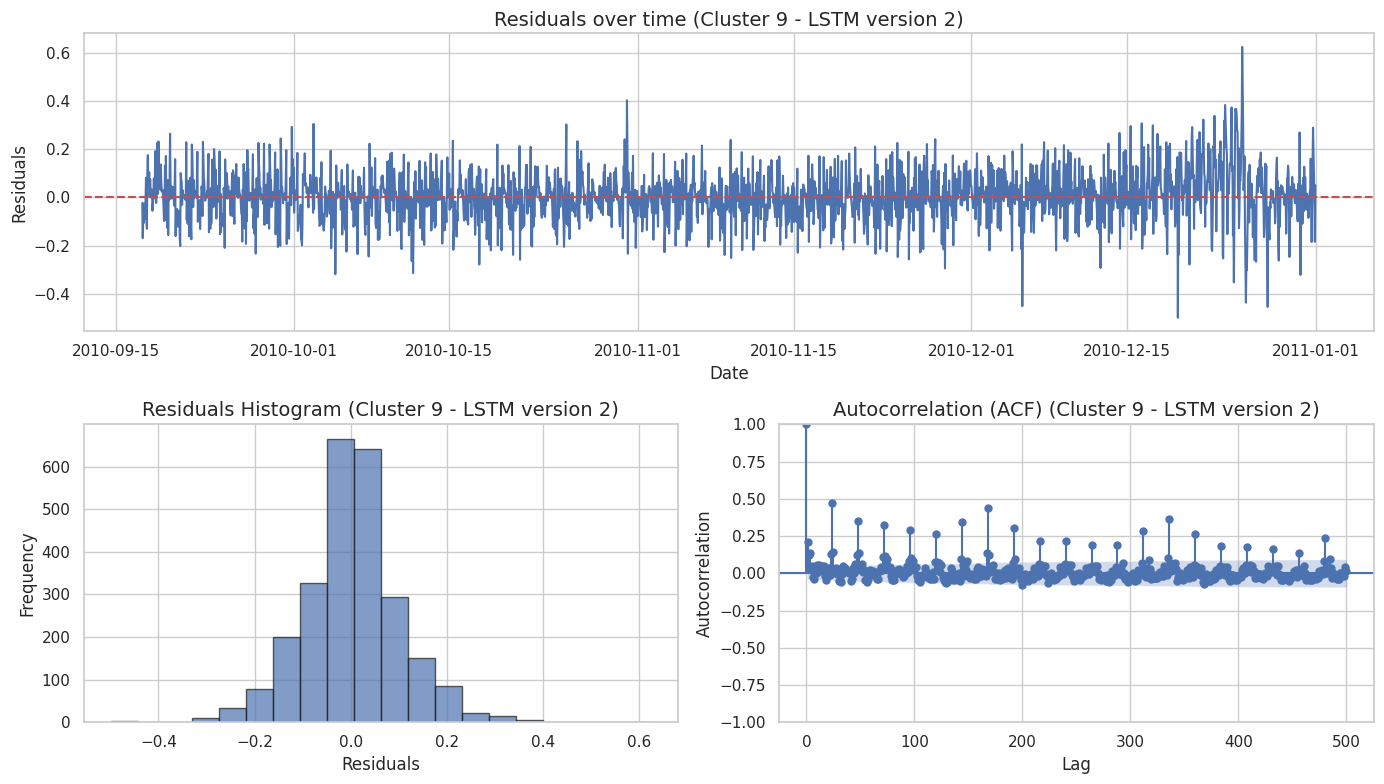

In [ ]:
# Prepare test set
test_size = len(X) - threshold
test_full = data_scaled[-(test_size + window_size):]

X_test = []
for i in range(window_size, len(test_full)):
    X_test.append(test_full[i - window_size : i, :])
X_test = np.array(X_test)

# Calculate predictions
y_pred_9_scaled = model_9_new.predict(X_test).flatten()

# Inverse transform target column
y_pred_9_new = (y_pred_9_scaled - scaler.min_[0]) / scaler.scale_[0]

# Extract actual values
actuals_9 = data[threshold + window_size :, 0]

# Calculate and plot residuals
residuals_9_new = pd.Series(actuals_9 - y_pred_9_new, index = df.index[threshold + window_size:])
plot_residuals(residuals_9_new, title_suffix = 'Cluster 9 - LSTM version 2')

In [ ]:
ljungbox_test(residuals_9_new)

,p-value,Result
24,6.193181e-168,Autocorrelation
168,0.000000e+00,Autocorrelation


Nonostante i miglioramenti evidenziati dai grafici, rimane comunque un certo grado di autocorrelazione tra i residui.

## 5. Conclusioni e raccomandazioni

Nella scelta del modello ottimale per ciascun cluster hanno influito sia le rappresentazioni grafiche delle previsioni, sia i risultati ottenuti con le metriche di valutazione. Considerato che il modello baseline AR(1) era già stato escluso per tutti e tre i cluster, mostriamo nuovamente qui di seguito i grafici dei modelli classici e i modelli ricorrenti per ciascun cluster e la tabella riassuntiva delle metriche di valutazione.

### Cluster 26

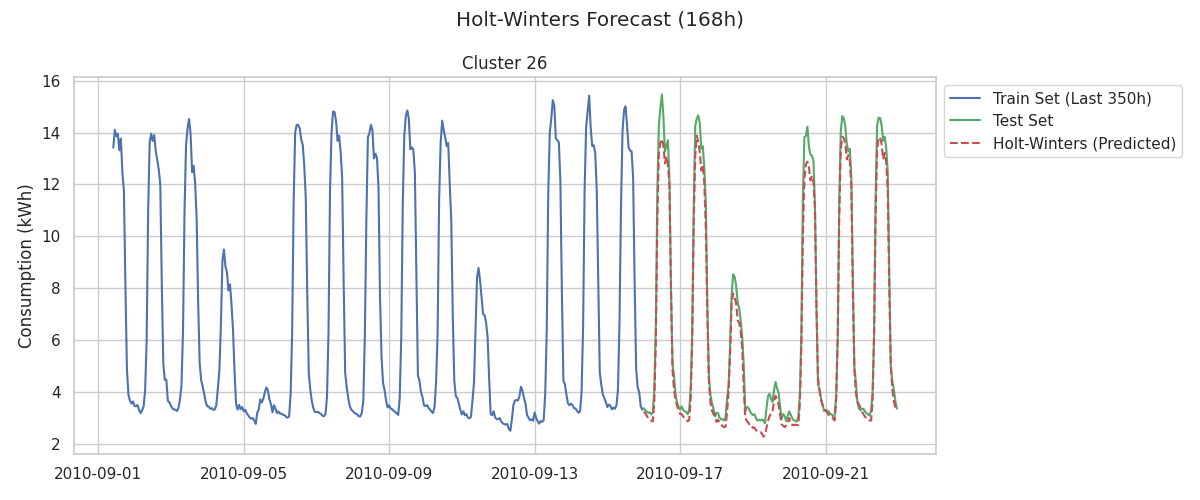

In [ ]:
img_hw_26 = Image.open('hw_26_test_vs_pred.png')
display(img_hw_26)

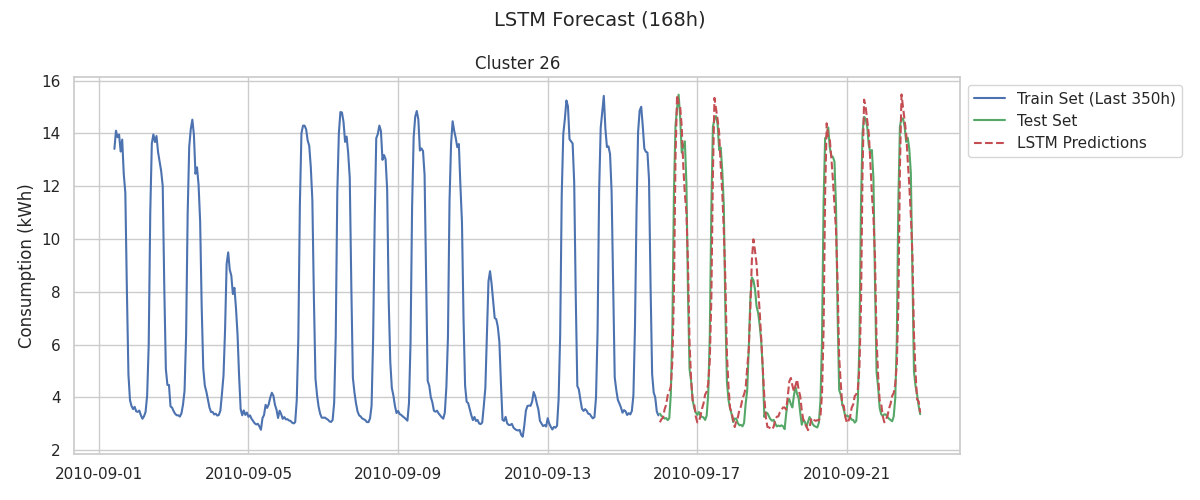

In [ ]:
img_lstm_26 = Image.open('lstm_26_test_vs_pred.png')
display(img_lstm_26)

### Cluster 9

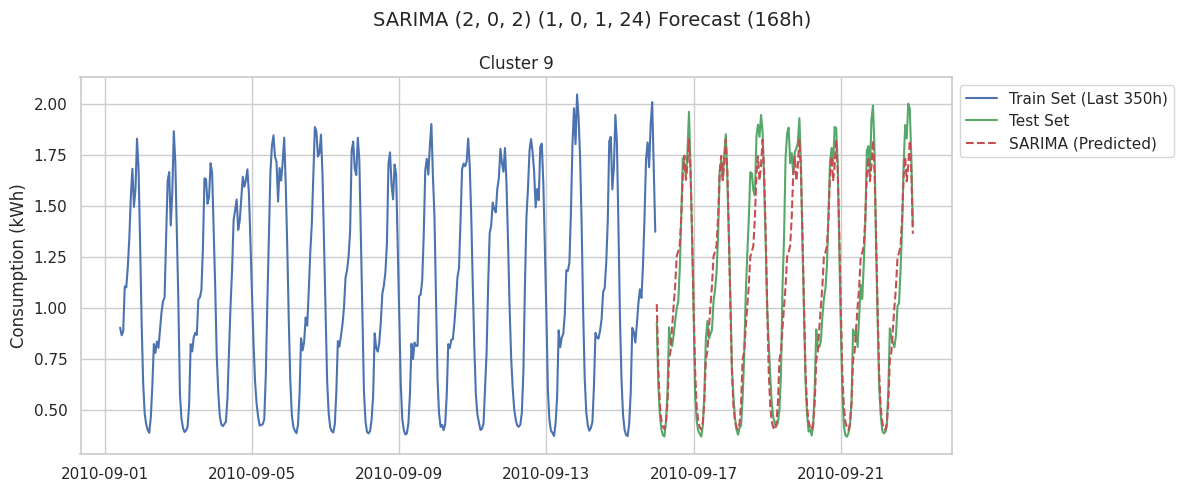

In [ ]:
img_sarima_9 = Image.open('sarima_9_test_vs_pred.png')
display(img_sarima_9)

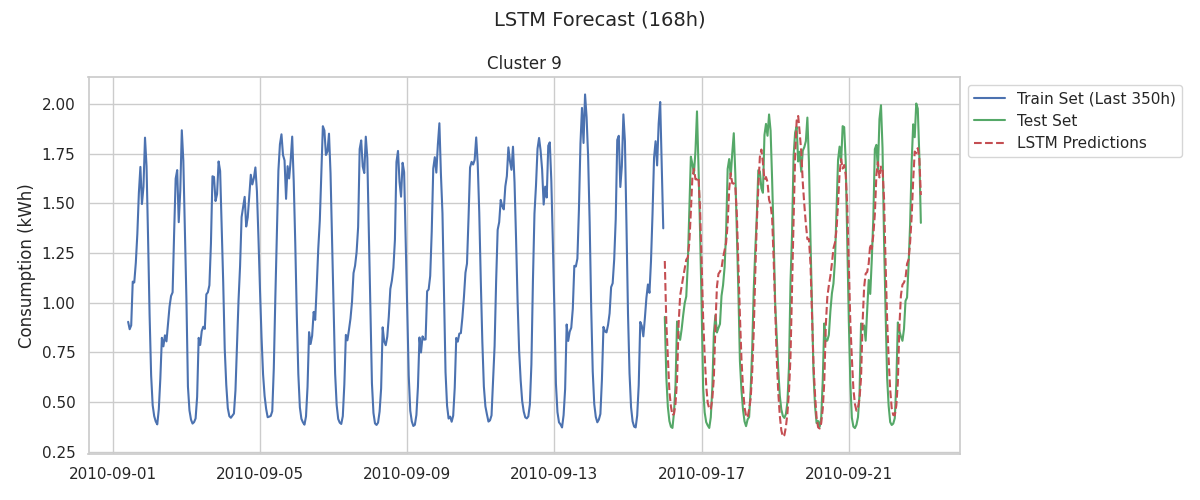

In [ ]:
img_lstm_9 = Image.open('lstm_9_test_vs_pred.png')
display(img_lstm_9)

### Cluster 24

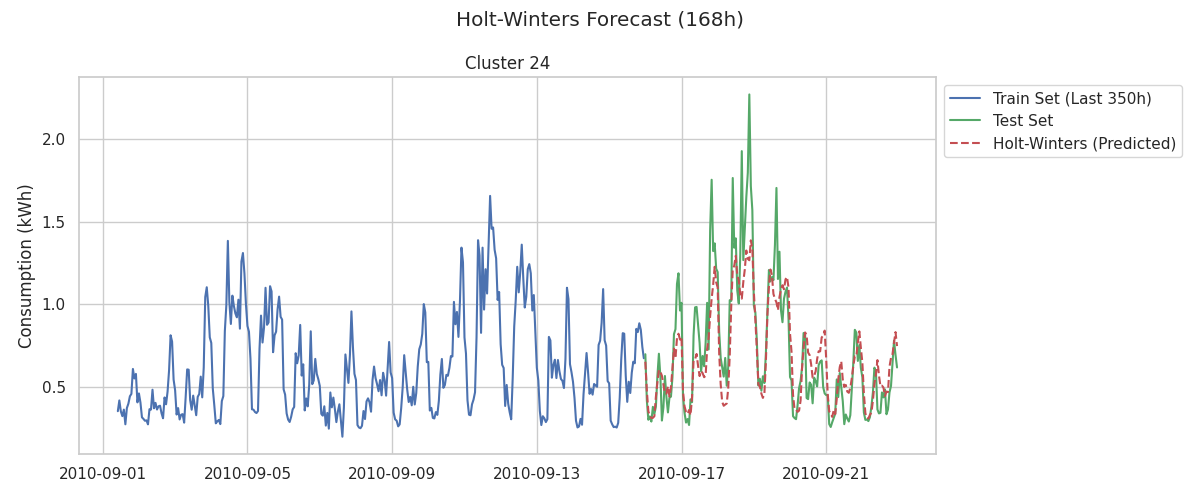

In [ ]:
img_hw_24 = Image.open('hw_24_test_vs_pred.png')
display(img_hw_24)

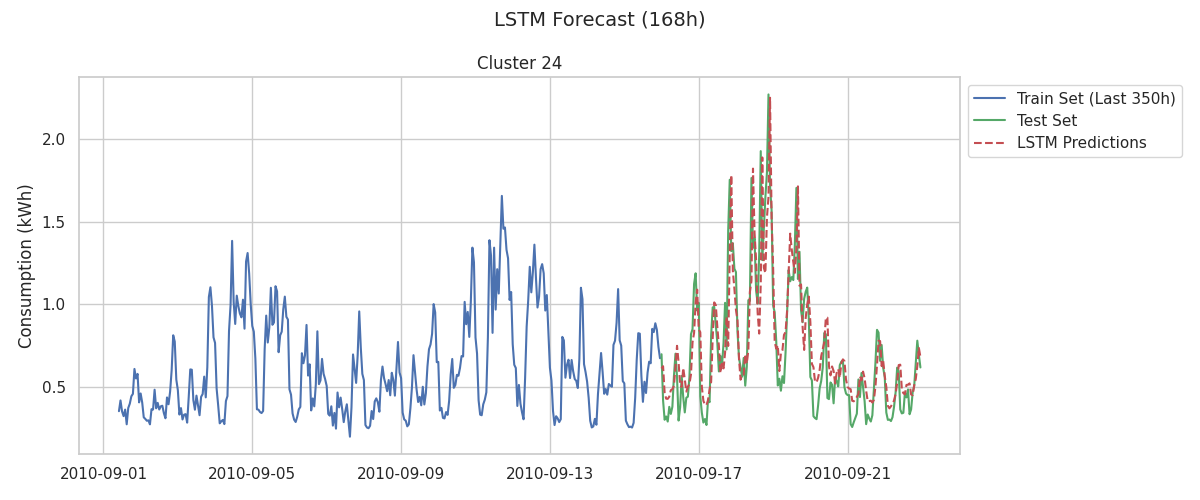

In [ ]:
img_lstm_24 = Image.open('lstm_24_test_vs_pred.png')
display(img_lstm_24)

### Tabella riepilogativa delle metriche

In [ ]:
df_evaluation_metrics.style.apply(highlight_best_model, axis = None).format(subset = ['MAE', 'RMSE', 'MAPE (%)'], formatter = '{:.2f}')

,Cluster,Model,MAE,RMSE,MAPE (%)
0,cluster_26,AR(1),4.29,5.31,66.56
1,cluster_26,ARIMA/SARIMA,2.44,3.52,31.88
2,cluster_26,Holt-Winters,0.45,0.56,7.66
3,cluster_26,LSTM,0.93,1.44,12.44
4,cluster_9,AR(1),0.59,0.70,65.62
5,cluster_9,ARIMA/SARIMA,0.24,0.38,15.99
6,cluster_9,LSTM,0.22,0.30,18.86
7,cluster_24,AR(1),0.32,0.39,69.37
8,cluster_24,ARIMA/SARIMA,0.25,0.35,38.12
9,cluster_24,Holt-Winters,0.15,0.21,21.59


Da un punto di vista grafico, per il cluster 26 e il cluster 9 le previsioni del modello classico e del modello ricorrente con rete LSTM sono molto simili. Considerando però anche le metriche di valutazione, la scelta per il **cluster 26** ricade sul modello **Holt-Winters**, mentre per il **cluster 9** optiamo per il modello **LSTM**. Per il cluster 24, invece, la scelta risulta meno immediata. Considerando le metriche di valutazione, infatti, il modello Holt-Winters performa leggermente meglio, ma osservando i grafici delle previsioni, il modello LSTM risulta ricalcare i dati reali in maniera nettamente migliore. Pertanto, per il **cluster 24** optiamo per il modello **LSTM**.

I modelli proposti sembrano gestire efficacemente le numerose fluttuazioni dei dati, che sono tipici in contesti reali legati al consumo di energia elettrica. Dall'analisi condotta non risulta esserci un "vincitore" netto tra modelli classici e modelli ricorrenti; piuttosto, la tipologia di modello da addestrare sembra dipendere dalla struttura della serie storica. Pertanto, una strategia può essere quella di adottare un approccio ibrido, valutando il tradeoff tra il costo computazionale e l'interpretabilità dei modelli classici, da un lato, e l'elevata capacità di gestione di pattern complessi dei modelli ricorrenti, dall'altro.

Sicuramente, per un'applicabilità operativa in contesti reali sarebbe necessario gestire l'autocorrelazione riscontrata nei residui. Una soluzione da valutare potrebbe essere l'integrazione dei modelli con ulteriori feature esogene, per esempio legate al clima e alla temperatura, in quanto sono fattori che influiscono molto sui consumi e la disponibilità di energia elettrica.